<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/HW/01NAEX_Ex03_HW_Vesely.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 03: Randomized blocks and factorial designs

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapters 4 and 5.
Problem numbers follow the 8th edition.

**Homework solution:** Mateusz Vesely

## Learning goals

* Analyse a randomized complete block design (RCBD) in `statsmodels` and see what happens when the blocks are ignored.
* Quantify the benefit of blocking with the relative efficiency of the RCBD.
* Compare treatment means with Fisher's LSD and Tukey's HSD using the error mean square of the *correct* model.
* Fit and interpret a two-factor factorial model with interaction: interaction plots, ANOVA, simple effects, residual analysis.
* Test for nonadditivity when there is only one observation per cell (Tukey's one-degree-of-freedom test).
* Compute the power of the ANOVA $F$-test from the noncentral $F$ distribution and choose the number of blocks or replicates.
* Model a quantitative factor with response curves and surfaces; analyse a three-factor factorial and a factorial run in blocks.

## Setup

Run this cell first. Besides the standard imports it defines three small helper functions used throughout the notebook:

* `tukey_from_model()` - Tukey's HSD with $MS_E$ and $df_E$ taken from a fitted model with blocks or several factors.
  (`pairwise_tukeyhsd()` from `statsmodels` always fits a one-way model, so it uses the wrong error mean square in these designs.)
* `tukey_nonadditivity()` - Tukey's one-degree-of-freedom test for nonadditivity (one observation per cell).
* `anova_power()` - power of the ANOVA $F$-test for a given noncentrality parameter $\lambda$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.graphics.factorplots import interaction_plot
from statsmodels.stats.multicomp import pairwise_tukeyhsd

URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/"


def tukey_from_model(model, data, factor, response, alpha=0.05):
    """Tukey's HSD for the levels of `factor`, using MS_E and df_E of a fitted model.

    Balanced data are assumed (the same number of observations at every level of `factor`).
    """
    mse, dfe = model.mse_resid, model.df_resid
    means = data.groupby(factor, observed=True)[response].mean()
    n = data.groupby(factor, observed=True)[response].count().iloc[0]
    k = len(means)
    se = np.sqrt(mse / n)
    hsd = stats.studentized_range.ppf(1 - alpha, k, dfe) * se
    rows = []
    levels = list(means.index)
    for i in range(k):
        for j in range(i + 1, k):
            diff = means.iloc[j] - means.iloc[i]
            rows.append({"pair": f"{levels[j]} - {levels[i]}", "diff": diff,
                         "lower": diff - hsd, "upper": diff + hsd,
                         "p_adj": stats.studentized_range.sf(abs(diff) / se, k, dfe),
                         "reject": abs(diff) > hsd})
    print(f"MS_E = {mse:.4g}, df_E = {dfe:.0f}, n per level = {n}, HSD = {hsd:.4g}")
    return pd.DataFrame(rows)


def tukey_nonadditivity(data, response, row, col):
    """Tukey's one-degree-of-freedom test for nonadditivity in a two-way layout with one observation per cell.

    The covariate q = (row mean - grand mean) * (column mean - grand mean) is added to the additive model;
    its sequential sum of squares is SS_N (1 df) and the remaining residual is SS_Error.
    """
    d = data.copy()
    g = d[response].mean()
    d["q_nonadd"] = ((d.groupby(row)[response].transform("mean") - g)
                     * (d.groupby(col)[response].transform("mean") - g))
    fit = smf.ols(f"{response} ~ C({row}) + C({col}) + q_nonadd", data=d).fit()
    return sm.stats.anova_lm(fit, typ=1)


def anova_power(lam, df1, df2, alpha=0.05):
    """Power of the ANOVA F-test: P(F'(df1, df2, lam) > F_{1-alpha; df1, df2})."""
    return stats.ncf.sf(stats.f.ppf(1 - alpha, df1, df2), df1, df2, lam)

## 1. Lecture example: hardness testing experiment (RCBD)

Lecture 3 analysed the hardness testing experiment (Montgomery, Section 4.1, data from Problem 4.7). A machine measures hardness by
pressing a tip into a metal test coupon. Four types of tips are compared; the coupons may differ, so each of the four
coupons is used as a **block** and all four tips are tested on every coupon in random order. The response is the
Rockwell C-scale reading minus 40.

The data set is small, so we type it in.

In [2]:
y = [[9.3, 9.4, 9.6, 10.0],     # tip 1, coupons 1-4
     [9.4, 9.3, 9.8, 9.9],      # tip 2
     [9.2, 9.4, 9.5, 9.7],      # tip 3
     [9.7, 9.6, 10.0, 10.2]]    # tip 4
hard = pd.DataFrame([(t + 1, c + 1, y[t][c]) for t in range(4) for c in range(4)],
                    columns=["Tip", "Coupon", "y"])
hard.pivot(index="Tip", columns="Coupon", values="y")

Coupon,1,2,3,4
Tip,,,,
1,9.3,9.4,9.6,10.0
2,9.4,9.3,9.8,9.9
3,9.2,9.4,9.5,9.7
4,9.7,9.6,10.0,10.2


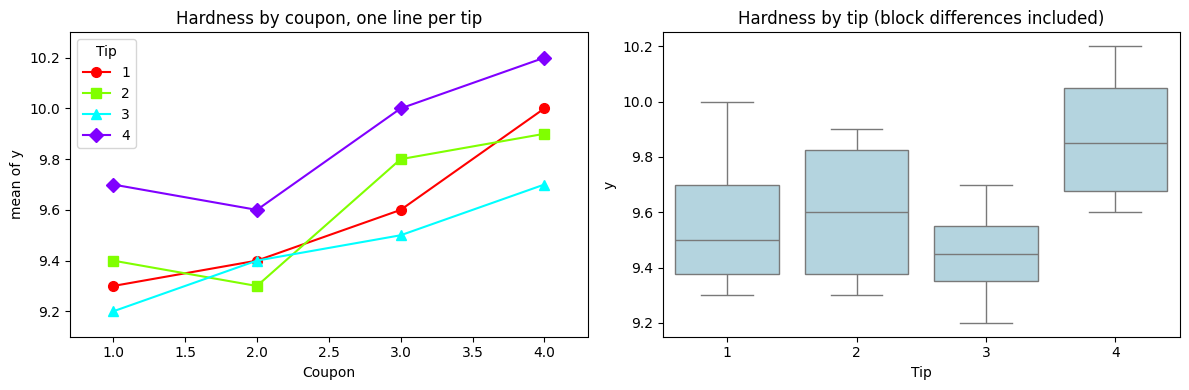

In [3]:
# Left: readings of each tip across the coupons (blocks); right: tips compared within coupons.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
interaction_plot(hard["Coupon"], hard["Tip"], hard["y"], ax=axes[0], markers=["o", "s", "^", "D"], ms=7)
axes[0].set_title("Hardness by coupon, one line per tip")
sns.boxplot(data=hard, x="Tip", y="y", ax=axes[1], color="lightblue")
axes[1].set_title("Hardness by tip (block differences included)")
plt.tight_layout(); plt.show()

The lines in the left plot are roughly parallel: the coupons shift all readings up or down by a similar amount
(block effect) and tip 4 reads highest on every coupon. The boxplot on the right mixes the coupon-to-coupon variability into
the spread of each tip, which hides the tip effect.

### ANOVA of the RCBD and the same data analysed as a completely randomized design

In [4]:
rcbd = smf.ols("y ~ C(Tip) + C(Coupon)", data=hard).fit()
crd = smf.ols("y ~ C(Tip)", data=hard).fit()
print("RCBD: tips + coupons (blocks)")
display(sm.stats.anova_lm(rcbd, typ=2))
print("CRD: blocks ignored")
display(sm.stats.anova_lm(crd, typ=2))
print(f"MS_E RCBD = {rcbd.mse_resid:.5f}, MS_E CRD = {crd.mse_resid:.5f}, ratio = {crd.mse_resid / rcbd.mse_resid:.2f}")

RCBD: tips + coupons (blocks)


,sum_sq,df,F,PR(>F)
C(Tip),0.385,3.0,14.4375,0.000871
C(Coupon),0.825,3.0,30.9375,0.000045
Residual,0.080,9.0,NaN,NaN


CRD: blocks ignored


,sum_sq,df,F,PR(>F)
C(Tip),0.385,3.0,1.701657,0.219568
Residual,0.905,12.0,NaN,NaN


MS_E RCBD = 0.00889, MS_E CRD = 0.07542, ratio = 8.48


In the RCBD the tip effect is highly significant ($F_0 = 14.44$, $p = 0.0009$). Ignoring the blocks moves $SS_{Coupon}$ into
the error term, $MS_E$ grows about 8.5 times and the tip effect is no longer detected ($p = 0.22$).

### Relative efficiency of the RCBD

How many more observations would a completely randomized design need to estimate the tip means as precisely
(Montgomery, Supplemental Material S4.1)?

$$
R = \frac{(df_b+1)(df_r+3)}{(df_b+3)(df_r+1)}\,\frac{\hat\sigma_r^2}{\hat\sigma_b^2},\qquad
\hat\sigma_r^2 = \frac{(b-1)MS_{Blocks} + b(a-1)MS_E}{ab-1},\qquad \hat\sigma_b^2 = MS_E,
$$

with $df_b = (a-1)(b-1)$ and $df_r = a(b-1)$ the error degrees of freedom of the RCBD and of the CRD.

In [5]:
def relative_efficiency(model, block, a, b):
    """Relative efficiency of an RCBD with a treatments and b blocks with respect to a CRD."""
    tab = sm.stats.anova_lm(model, typ=2)
    ms_block = tab.loc[block, "sum_sq"] / tab.loc[block, "df"]
    mse = model.mse_resid
    sigma2_crd = ((b - 1) * ms_block + b * (a - 1) * mse) / (a * b - 1)
    df_b, df_r = (a - 1) * (b - 1), a * (b - 1)
    correction = (df_b + 1) * (df_r + 3) / ((df_b + 3) * (df_r + 1))
    return sigma2_crd / mse, correction * sigma2_crd / mse

ratio, R = relative_efficiency(rcbd, "C(Coupon)", a=4, b=4)
print(f"variance ratio = {ratio:.2f}, relative efficiency R = {R:.2f}")

variance ratio = 6.99, relative efficiency R = 6.72


A completely randomized design would need about 6.7 times as many runs per tip to reach the same precision.

### Which tips differ?

Fisher's LSD and Tukey's HSD must use $MS_E$ and $df_E$ of the RCBD model. For comparison, the last output shows what
`pairwise_tukeyhsd()` reports: it fits a one-way model (blocks ignored) and finds no difference at all.

In [6]:
mse, dfe = rcbd.mse_resid, rcbd.df_resid
b = hard["Coupon"].nunique()
lsd = stats.t.ppf(0.975, dfe) * np.sqrt(2 * mse / b)
print("Tip means:", hard.groupby("Tip")["y"].mean().round(3).to_dict())
print(f"Fisher LSD = {lsd:.4f}")

tukey_tips = tukey_from_model(rcbd, hard, "Tip", "y")
tukey_tips["|diff| > LSD"] = tukey_tips["diff"].abs() > lsd
display(tukey_tips.round(4))

print("WRONG for an RCBD - pairwise_tukeyhsd() ignores the blocks:")
print(pairwise_tukeyhsd(hard["y"], hard["Tip"]))

Tip means: {1: 9.575, 2: 9.6, 3: 9.45, 4: 9.875}
Fisher LSD = 0.1508
MS_E = 0.008889, df_E = 9, n per level = 4, HSD = 0.2081


,pair,diff,lower,upper,p_adj,reject,|diff| > LSD
0,2 - 1,0.025,-0.1831,0.2331,0.9809,False,False
1,3 - 1,-0.125,-0.3331,0.0831,0.3028,False,False
2,4 - 1,0.300,0.0919,0.5081,0.0067,True,True
3,3 - 2,-0.150,-0.3581,0.0581,0.1816,False,False
4,4 - 2,0.275,0.0669,0.4831,0.0113,True,True
5,4 - 3,0.425,0.2169,0.6331,0.0006,True,True


WRONG for an RCBD - pairwise_tukeyhsd() ignores the blocks:
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     1      2    0.025 0.9992 -0.5515 0.6015  False
     1      3   -0.125 0.9157 -0.7015 0.4515  False
     1      4      0.3 0.4431 -0.2765 0.8765  False
     2      3    -0.15 0.8653 -0.7265 0.4265  False
     2      4    0.275 0.5135 -0.3015 0.8515  False
     3      4    0.425 0.1816 -0.1515 1.0015  False
---------------------------------------------------


Tip 4 gives higher readings than tips 1, 2 and 3; tips 1, 2 and 3 do not differ (the comparison 3 - 2 is borderline for LSD).

### Model adequacy

Residuals versus fitted values, normal probability plot and residuals versus both factors. With one observation per cell
we cannot fit the tip $\times$ coupon interaction, but Tukey's one-degree-of-freedom test checks the additivity assumption.

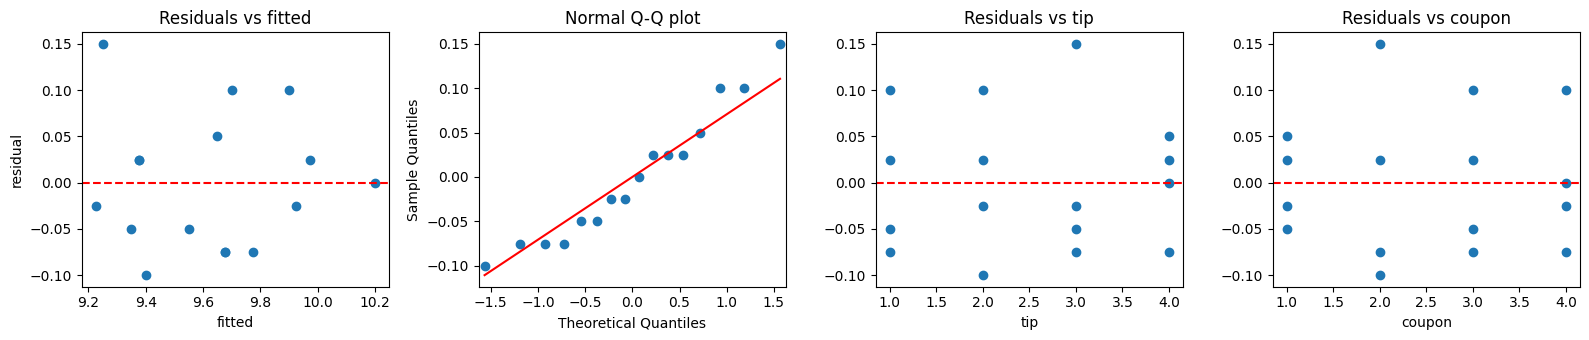

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.9395749935367946, pvalue=0.3438404916041873)

Tukey's test for nonadditivity (row q_nonadd):


,df,sum_sq,mean_sq,F,PR(>F)
C(Tip),3.0,0.38500,0.12833,13.52306,0.00169
C(Coupon),3.0,0.82500,0.27500,28.97798,0.00012
q_nonadd,1.0,0.00408,0.00408,0.42996,0.53041
Residual,8.0,0.07592,0.00949,NaN,NaN


In [7]:
res, fit = rcbd.resid, rcbd.fittedvalues
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].scatter(fit, res); axes[0].axhline(0, color="red", ls="--"); axes[0].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
sm.qqplot(res, line="s", ax=axes[1]); axes[1].set_title("Normal Q-Q plot")
axes[2].scatter(hard["Tip"], res); axes[2].axhline(0, color="red", ls="--"); axes[2].set(xlabel="tip", title="Residuals vs tip")
axes[3].scatter(hard["Coupon"], res); axes[3].axhline(0, color="red", ls="--"); axes[3].set(xlabel="coupon", title="Residuals vs coupon")
plt.tight_layout(); plt.show()

print("Shapiro-Wilk on residuals:", stats.shapiro(res))
print("\nTukey's test for nonadditivity (row q_nonadd):")
display(tukey_nonadditivity(hard, "y", "Tip", "Coupon").round(5))

No pattern in the residuals, normality is acceptable and there is no evidence of nonadditivity ($p = 0.53$).

### How many blocks?

We want to detect a true maximum difference of $D = 0.4$ between two tip means with high probability, with
$\sigma = 0.1$. For the least favourable configuration (two means $D$ apart, the others in the middle)
$\lambda = bD^2/(2\sigma^2)$, $\Phi^2 = \lambda/a$, and $F_0 \sim F_{a-1,(a-1)(b-1)}(\lambda)$ under $H_1$.

In [8]:
a, D, sigma = 4, 0.4, 0.1
rows = []
for b in range(3, 9):
    lam = b * D**2 / (2 * sigma**2)
    df1, df2 = a - 1, (a - 1) * (b - 1)
    rows.append({"blocks b": b, "Phi": np.sqrt(lam / a), "lambda": lam, "df2": df2,
                 "power": anova_power(lam, df1, df2)})
display(pd.DataFrame(rows).round(4))

,blocks b,Phi,lambda,df2,power
0,3,2.4495,24.0,6,0.8461
1,4,2.8284,32.0,9,0.9757
2,5,3.1623,40.0,12,0.9972
3,6,3.4641,48.0,15,0.9997
4,7,3.7417,56.0,18,1.0000
5,8,4.0000,64.0,21,1.0000


## 2. Lecture example: battery life (two-factor factorial)

Montgomery, Example 5.1: the effective life (hours) of a battery for three plate materials and three temperatures
(15, 70, 125 $^\circ$F), $n = 4$ replicates, all 36 runs in random order. Questions: what effects do material and
temperature have on life, and is there a material that gives uniformly long life regardless of temperature?

In [9]:
bat = pd.read_csv(URL + "battery.txt", sep=r"\s+")
print(bat.shape)
display(bat.pivot_table(index="Material", columns="Temperature", values="Life", aggfunc="mean"))
display(bat.pivot_table(index="Material", columns="Temperature", values="Life", aggfunc="std").round(2))

(36, 3)


Temperature,15,70,125
Material,,,
1,134.75,57.25,57.5
2,155.75,119.75,49.5
3,144.00,145.75,85.5


Temperature,15,70,125
Material,,,
1,45.35,23.60,26.85
2,25.62,12.66,19.26
3,25.97,22.54,19.28


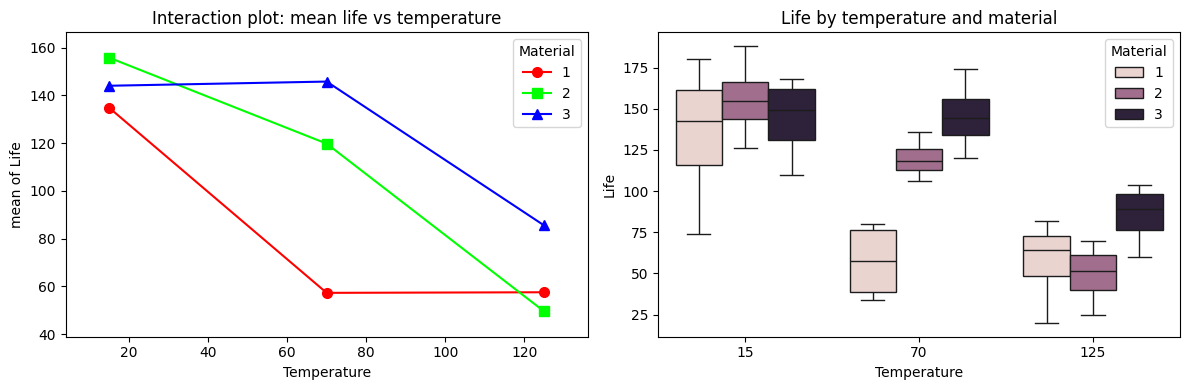

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
interaction_plot(bat["Temperature"], bat["Material"], bat["Life"], ax=axes[0], markers=["o", "s", "^"], ms=7)
axes[0].set_title("Interaction plot: mean life vs temperature")
sns.boxplot(data=bat, x="Temperature", y="Life", hue="Material", ax=axes[1])
axes[1].set_title("Life by temperature and material")
plt.tight_layout(); plt.show()

The lines are not parallel: material 1 loses most of its life already at 70 $^\circ$F, materials 2 and 3 only at 125 $^\circ$F.

### ANOVA with and without interaction

In [11]:
full = smf.ols("Life ~ C(Material) * C(Temperature)", data=bat).fit()
add = smf.ols("Life ~ C(Material) + C(Temperature)", data=bat).fit()
display(sm.stats.anova_lm(full, typ=2))
display(sm.stats.anova_lm(add, typ=2))
print("F-test for the interaction (additive vs full model):")
display(sm.stats.anova_lm(add, full))

,sum_sq,df,F,PR(>F)
C(Material),10683.722222,2.0,7.911372,1.976083e-03
C(Temperature),39118.722222,2.0,28.967692,1.908596e-07
C(Material):C(Temperature),9613.777778,4.0,3.559535,1.861117e-02
Residual,18230.750000,27.0,NaN,NaN


,sum_sq,df,F,PR(>F)
C(Material),10683.722222,2.0,5.947226,0.006515
C(Temperature),39118.722222,2.0,21.775919,0.000001
Residual,27844.527778,31.0,NaN,NaN


F-test for the interaction (additive vs full model):


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,31.0,27844.527778,0.0,NaN,NaN,NaN
1,27.0,18230.750000,4.0,9613.777778,3.559535,0.018611


### Model adequacy

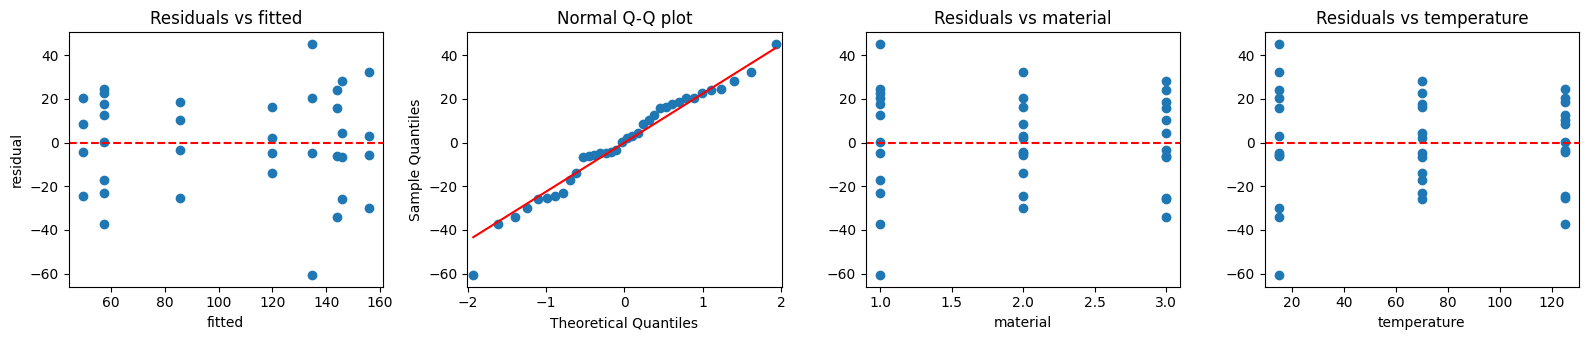

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.9760570230884389, pvalue=0.6117266783860501)
Levene (Brown-Forsythe) across the 9 cells: LeveneResult(statistic=0.7995970449966421, pvalue=0.6081330500874296)


In [12]:
res, fit = full.resid, full.fittedvalues
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].scatter(fit, res); axes[0].axhline(0, color="red", ls="--"); axes[0].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
sm.qqplot(res, line="s", ax=axes[1]); axes[1].set_title("Normal Q-Q plot")
axes[2].scatter(bat["Material"], res); axes[2].axhline(0, color="red", ls="--"); axes[2].set(xlabel="material", title="Residuals vs material")
axes[3].scatter(bat["Temperature"], res); axes[3].axhline(0, color="red", ls="--"); axes[3].set(xlabel="temperature", title="Residuals vs temperature")
plt.tight_layout(); plt.show()

cells_ = [g["Life"].to_numpy(dtype=float) for _, g in bat.groupby(["Material", "Temperature"])]
print("Shapiro-Wilk on residuals:", stats.shapiro(res))
print("Levene (Brown-Forsythe) across the 9 cells:", stats.levene(*cells_))

The residual plots show slightly larger spread for material 1 at 15 $^\circ$F (one low observation, 74 h), but no serious
violation of the assumptions.

### Comparisons of means

Tukey's HSD for the main effects uses $MS_E = 675.2$ with 27 df from the full model. Because the interaction is significant,
the main-effect comparisons average over very different situations; the **simple effects** (materials compared at a fixed
temperature, $n = 4$ per cell, pooled $MS_E$) answer the practical question.

In [13]:
display(tukey_from_model(full, bat, "Material", "Life").round(4))
display(tukey_from_model(full, bat, "Temperature", "Life").round(4))

MS_E = 675.2, df_E = 27, n per level = 12, HSD = 26.3


,pair,diff,lower,upper,p_adj,reject
0,2 - 1,25.1667,-1.1357,51.4690,0.0628,False
1,3 - 1,41.9167,15.6143,68.2190,0.0014,True
2,3 - 2,16.7500,-9.5523,43.0523,0.2718,False


MS_E = 675.2, df_E = 27, n per level = 12, HSD = 26.3


,pair,diff,lower,upper,p_adj,reject
0,70 - 15,-37.2500,-63.5523,-10.9477,0.0044,True
1,125 - 15,-80.6667,-106.9690,-54.3643,0.0000,True
2,125 - 70,-43.4167,-69.7190,-17.1143,0.0010,True


In [14]:
mse, dfe = full.mse_resid, full.df_resid
T = stats.studentized_range.ppf(0.95, 3, dfe) * np.sqrt(mse / 4)
print(f"Critical difference for materials within one temperature: T = {T:.2f}")
rows = []
for temp, sub in bat.groupby("Temperature"):
    m = sub.groupby("Material")["Life"].mean()
    for i, j in [(1, 2), (1, 3), (2, 3)]:
        rows.append({"Temperature": temp, "pair": f"{j} - {i}", "diff": m[j] - m[i], "significant": abs(m[j] - m[i]) > T})
pd.DataFrame(rows).pivot(index="Temperature", columns="pair", values="diff")

Critical difference for materials within one temperature: T = 45.56


pair,2 - 1,3 - 1,3 - 2
Temperature,,,
15,21.0,9.25,-11.75
70,62.5,88.50,26.00
125,-8.0,28.00,36.00


The materials differ only at 70 $^\circ$F (materials 2 and 3 better than 1). Material 3 gives long life at all three temperatures,
so it is the most robust choice.

### Sample size

How many replicates are needed to detect a difference of $D = 40$ h between two material means with $\sigma = 25$ h?
For factor $A$: $\Phi^2 = nbD^2/(2a\sigma^2)$, $\lambda = a\Phi^2$, $\nu_1 = a-1$, $\nu_2 = ab(n-1)$.

In [15]:
a = b = 3
D, sigma = 40, 25
rows = []
for n in [2, 3, 4, 5]:
    lam = n * b * D**2 / (2 * sigma**2)
    rows.append({"n": n, "Phi": np.sqrt(lam / a), "lambda": lam, "df2": a * b * (n - 1),
                 "power": anova_power(lam, a - 1, a * b * (n - 1))})
display(pd.DataFrame(rows).round(3))

,n,Phi,lambda,df2,power
0,2,1.600,7.68,9,0.542
1,3,1.960,11.52,18,0.803
2,4,2.263,15.36,27,0.923
3,5,2.530,19.20,36,0.972


### Response curves

Temperature is quantitative. With three levels we can fit at most a quadratic in temperature; letting the linear and
quadratic terms interact with material decomposes $SS_{Temperature}$ and $SS_{Material:Temperature}$ into single-degree-of-freedom parts.

,df,sum_sq,mean_sq,F,PR(>F)
C(Material),2.0,10683.722222,5341.861111,7.911372,1.976083e-03
T,1.0,39042.666667,39042.666667,57.822745,3.525248e-08
C(Material):T,2.0,2315.083333,1157.541667,1.714336,1.991088e-01
I(T ** 2),1.0,76.055556,76.055556,0.112639,7.397530e-01
C(Material):I(T ** 2),2.0,7298.694444,3649.347222,5.404735,1.061214e-02
Residual,27.0,18230.750000,675.212963,NaN,NaN


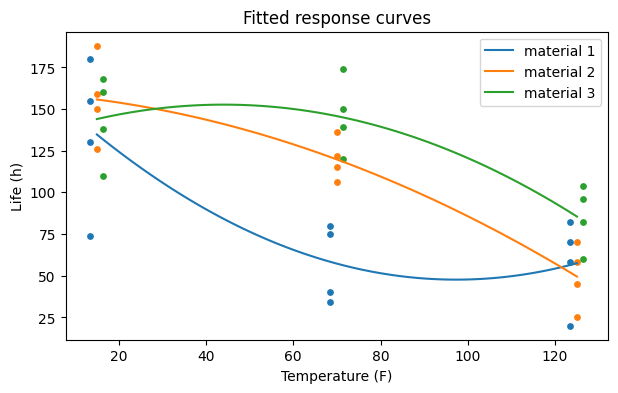

In [16]:
bat["T"] = bat["Temperature"].astype(float)
rc = smf.ols("Life ~ C(Material) + T + I(T**2) + C(Material):T + C(Material):I(T**2)", data=bat).fit()
display(sm.stats.anova_lm(rc, typ=1))

grid = np.linspace(15, 125, 100)
fig, ax = plt.subplots(figsize=(7, 4))
for mat, colour in zip([1, 2, 3], ["C0", "C1", "C2"]):
    pred = rc.predict(pd.DataFrame({"Material": mat, "T": grid}))
    ax.plot(grid, pred, color=colour, label=f"material {mat}")
    sub = bat[bat["Material"] == mat]
    ax.scatter(sub["T"] + (mat - 2) * 1.5, sub["Life"], color=colour, s=15)
ax.set(xlabel="Temperature (F)", ylabel="Life (h)", title="Fitted response curves")
ax.legend(); plt.show()

## 3. Lecture examples: blocking in a factorial, three factors, response surface

### Radar target detection (Example 5.6): a factorial run in blocks

Factors: filter type (2) and ground clutter (low, medium, high). Each of four operators runs all six combinations in
random order, so the operator is a **block**. The model is $y_{ijk} = \mu + \tau_i + \beta_j + (\tau\beta)_{ij} + \delta_k + \varepsilon_{ijk}$.

With operators as blocks


,sum_sq,df,F,PR(>F)
C(Operator),402.166667,3.0,12.089178,2.771485e-04
C(Filter),1066.666667,1.0,96.192385,6.446793e-08
C(Ground),335.583333,2.0,15.131513,2.527013e-04
C(Filter):C(Ground),77.083333,2.0,3.475701,5.750655e-02
Residual,166.333333,15.0,NaN,NaN


Blocks ignored


,sum_sq,df,F,PR(>F)
C(Filter),1066.666667,1.0,33.773087,0.000017
C(Ground),335.583333,2.0,5.312665,0.015371
C(Filter):C(Ground),77.083333,2.0,1.220317,0.318422
Residual,568.500000,18.0,NaN,NaN


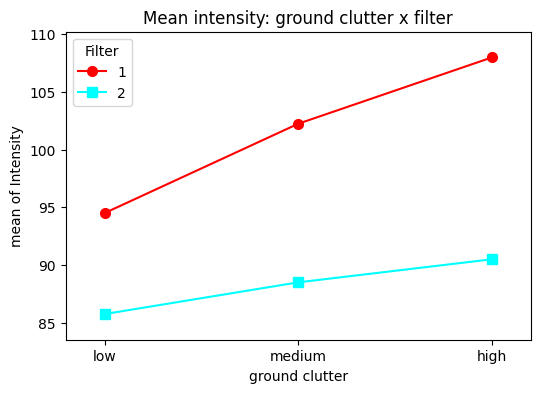

In [17]:
radar = pd.read_csv(URL + "intensity.txt", sep=r"\s+")
radar["Ground"] = pd.Categorical(radar["Ground"], categories=["low", "medium", "high"], ordered=True)
blk = smf.ols("Intensity ~ C(Operator) + C(Filter) * C(Ground)", data=radar).fit()
noblk = smf.ols("Intensity ~ C(Filter) * C(Ground)", data=radar).fit()
print("With operators as blocks"); display(sm.stats.anova_lm(blk, typ=2))
print("Blocks ignored"); display(sm.stats.anova_lm(noblk, typ=2))

fig, ax = plt.subplots(figsize=(6, 4))
interaction_plot(radar["Ground"].cat.codes, radar["Filter"], radar["Intensity"], ax=ax, markers=["o", "s"], ms=7)
ax.set_xticks([0, 1, 2], radar["Ground"].cat.categories)
ax.set(xlabel="ground clutter", title="Mean intensity: ground clutter x filter"); plt.show()

### Soft drink bottling (Example 5.3): three factors

Deviation from the target fill height for carbonation (10, 12, 14 %), operating pressure (25, 30 psi) and line speed
(200, 250 bottles/min), two replicates.

,sum_sq,df,F,PR(>F)
C(Carbonation),252.750000,2.0,178.411765,1.186249e-09
C(Pressure),45.375000,1.0,64.058824,3.742257e-06
C(Speed),22.041667,1.0,31.117647,1.202174e-04
C(Carbonation):C(Pressure),5.250000,2.0,3.705882,5.580812e-02
C(Carbonation):C(Speed),0.583333,2.0,0.411765,6.714939e-01
C(Pressure):C(Speed),1.041667,1.0,1.470588,2.485867e-01
C(Carbonation):C(Pressure):C(Speed),1.083333,2.0,0.764706,4.868711e-01
Residual,8.500000,12.0,NaN,NaN


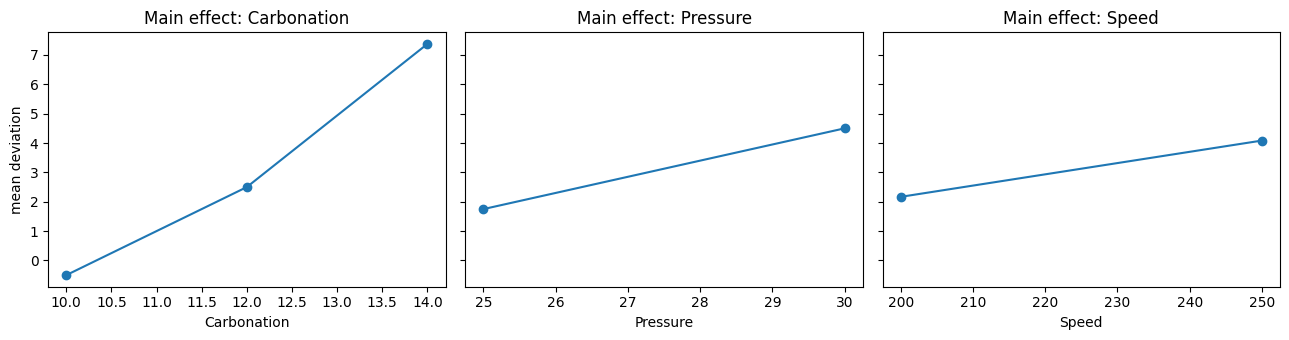

In [18]:
bot = pd.read_csv(URL + "bottling.txt", sep=r"\s+")
m3 = smf.ols("Deviation ~ C(Carbonation) * C(Pressure) * C(Speed)", data=bot).fit()
display(sm.stats.anova_lm(m3, typ=2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, factor in zip(axes, ["Carbonation", "Pressure", "Speed"]):
    bot.groupby(factor)["Deviation"].mean().plot(marker="o", ax=ax)
    ax.set_title(f"Main effect: {factor}"); ax.set_ylabel("mean deviation")
plt.tight_layout(); plt.show()

### Tool life (Example 5.5): response surface for two quantitative factors

Cutting angle (15, 20, 25 degrees) and cutting speed (125, 150, 175 in/min), two replicates. The full model with linear and
quadratic terms in both factors and all their products has 9 parameters, one per cell mean.

,df,sum_sq,mean_sq,F,PR(>F)
Angle,1.0,8.333333,8.333333,5.769231,0.039772
I(Angle ** 2),1.0,16.000000,16.000000,11.076923,0.008824
Speed,1.0,21.333333,21.333333,14.769231,0.003948
I(Speed ** 2),1.0,4.000000,4.000000,2.769231,0.130451
Angle:Speed,1.0,8.000000,8.000000,5.538462,0.043065
Angle:I(Speed ** 2),1.0,42.666667,42.666667,29.538462,0.000414
I(Angle ** 2):Speed,1.0,2.666667,2.666667,1.846154,0.207306
I(Angle ** 2):I(Speed ** 2),1.0,8.000000,8.000000,5.538462,0.043065
Residual,9.0,13.000000,1.444444,NaN,NaN


Intercept                     -1067.999999
Angle                           136.300000
I(Angle ** 2)                    -4.080000
Speed                            14.480000
I(Speed ** 2)                    -0.049600
Angle:Speed                      -1.864000
Angle:I(Speed ** 2)               0.006400
I(Angle ** 2):Speed               0.056000
I(Angle ** 2):I(Speed ** 2)      -0.000192
dtype: float64


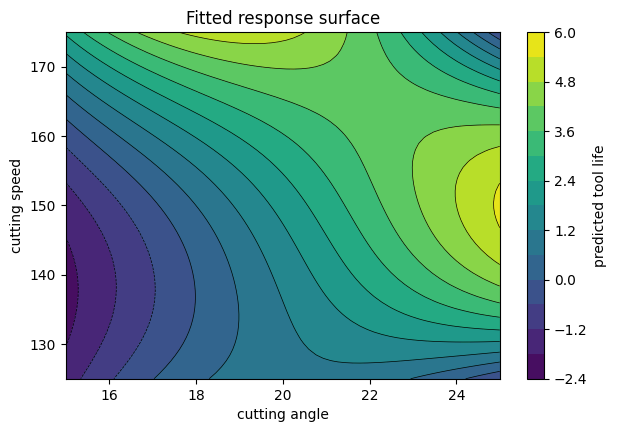

In [19]:
tool = pd.read_csv(URL + "toollife.txt", sep=r"\s+")
rs = smf.ols("Life ~ (Angle + I(Angle**2)) * (Speed + I(Speed**2))", data=tool).fit()
display(sm.stats.anova_lm(rs, typ=1))
print(rs.params.round(6))

A, S = np.meshgrid(np.linspace(15, 25, 60), np.linspace(125, 175, 60))
Z = rs.predict(pd.DataFrame({"Angle": A.ravel(), "Speed": S.ravel()})).to_numpy().reshape(A.shape)
fig, ax = plt.subplots(figsize=(7, 4.5))
cs = ax.contourf(A, S, Z, levels=12, cmap="viridis")
ax.contour(A, S, Z, levels=12, colors="k", linewidths=0.5)
fig.colorbar(cs, label="predicted tool life")
ax.set(xlabel="cutting angle", ylabel="cutting speed", title="Fitted response surface")
plt.show()

## In-class problems

Work in pairs; we discuss the results at the end of the class. For every test state the hypotheses, the test statistic,
the $p$-value and your decision.

### Problem 4.3 (with 4.16): chemical agents and cloth strength

A chemist wishes to test the effect of four chemical agents on the strength of a particular type of cloth. Because there might
be variability from one bolt to another, the chemist decides to use a randomized block design, with the bolts of cloth
considered as blocks. She selects five bolts and applies all four chemicals in random order to each bolt.
The resulting tensile strengths are:

| Chemical | Bolt 1 | Bolt 2 | Bolt 3 | Bolt 4 | Bolt 5 |
|---|---|---|---|---|---|
| 1 | 73 | 68 | 74 | 71 | 67 |
| 2 | 73 | 67 | 75 | 72 | 70 |
| 3 | 75 | 68 | 78 | 73 | 68 |
| 4 | 73 | 71 | 75 | 75 | 69 |

### Helper functions used in the solutions

The in-class and homework problems below use the RCBD model $y_{ij} = \mu + \tau_i + \beta_j + \varepsilon_{ij}$ and two- and three-factor fixed-effects
factorial models, always with $\varepsilon \sim N(0, \sigma^2)$ i.i.d. Besides `tukey_from_model()`, `tukey_nonadditivity()`,
`anova_power()` and `relative_efficiency()` defined earlier in this notebook, two small helpers are used repeatedly:

* `anova_report()` – prints the ANOVA table of a fitted `ols` model together with $MS_E$ and its degrees of freedom
  (the error term used by all tests and comparisons); very small $P$-values are shown in scientific notation;
* `residual_plots()` – residuals vs fitted values, normal Q-Q plot and residuals vs each factor, with the Shapiro-Wilk test,
  skewness/kurtosis and Levene's test of the residual spread across the levels of each factor. (With $n = 2$ observations per cell
  a Levene test across the *cells* is degenerate, because the two residuals of a cell are $\pm r$; the test is therefore run across
  the levels of each factor.)


In [20]:
# Helper functions used in all in-class and homework problems below
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})


def anova_report(model, typ=2):
    '''ANOVA table of a fitted ols model, with MS_E and df_E printed underneath. Returns the raw table.'''
    tab = sm.stats.anova_lm(model, typ=typ)
    shown = tab.copy()
    shown["PR(>F)"] = shown["PR(>F)"].map(lambda p: "" if pd.isna(p) else (f"{p:.4f}" if p >= 1e-4 else f"{p:.2e}"))
    display(shown.round(4))
    print(f"MS_E = {model.mse_resid:.4f} on {model.df_resid:.0f} df")
    return tab


def residual_plots(model, data, factors):
    '''Residuals vs fitted, normal Q-Q plot, residuals vs each factor; Shapiro-Wilk and Levene (by factor level) tests.'''
    res, fit = model.resid, model.fittedvalues
    k = 2 + len(factors)
    fig, axes = plt.subplots(1, k, figsize=(4 * k, 3.6))
    axes[0].scatter(fit, res); axes[0].axhline(0, color="red", ls="--")
    axes[0].set(xlabel="fitted value", ylabel="residual", title="Residuals vs fitted")
    sm.qqplot(res, line="s", ax=axes[1]); axes[1].set_title("Normal Q-Q plot")
    for ax, f in zip(axes[2:], factors):
        ax.scatter(data[f].astype(str), res); ax.axhline(0, color="red", ls="--")
        ax.set(xlabel=f, title=f"Residuals vs {f}")
    plt.tight_layout(); plt.show()
    sw = stats.shapiro(res)
    print(f"Shapiro-Wilk: W = {sw.statistic:.4f}, P = {sw.pvalue:.4f};  skewness = {stats.skew(res):.2f}, excess kurtosis = {stats.kurtosis(res):.2f}")
    for f in factors:
        groups = [g.to_numpy(dtype=float) for _, g in res.groupby(data[f])]
        lv = stats.levene(*groups)
        print(f"Levene (Brown-Forsythe) of the residuals across levels of {f}: W = {lv.statistic:.3f}, P = {lv.pvalue:.4f}")
    std_res = model.get_influence().resid_studentized_internal
    print(f"largest |standardized residual| = {np.abs(std_res).max():.2f}")


In [21]:
strength = [[73, 68, 74, 71, 67],
            [73, 67, 75, 72, 70],
            [75, 68, 78, 73, 68],
            [73, 71, 75, 75, 69]]
cloth = pd.DataFrame([(c + 1, b + 1, strength[c][b]) for c in range(4) for b in range(5)],
                     columns=["Chemical", "Bolt", "Strength"])
cloth.pivot(index="Chemical", columns="Bolt", values="Strength")

Bolt,1,2,3,4,5
Chemical,,,,,
1,73,68,74,71,67
2,73,67,75,72,70
3,75,68,78,73,68
4,73,71,75,75,69


**Question 1.** Plot the data (strength versus bolt, one line per chemical). What do you expect from the analysis?

**Procedure.** Strength versus bolt with one line per chemical (the interaction plot of the two-way layout) and a boxplot by
chemical. If the bolts differ a lot and the chemicals little, the four lines will move up and down together and the boxplots
by chemical will overlap.


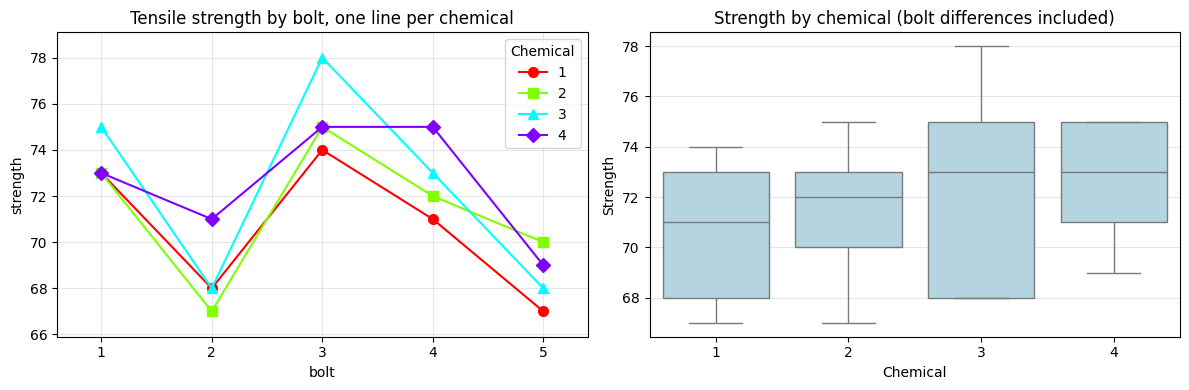

Chemical means: {1: 70.6, 2: 71.4, 3: 72.4, 4: 72.6}
Bolt means:     {1: 73.5, 2: 68.5, 3: 75.5, 4: 72.75, 5: 68.5}


In [22]:
# Q1: strength vs bolt, one line per chemical; boxplot by chemical
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
interaction_plot(cloth["Bolt"], cloth["Chemical"], cloth["Strength"], ax=axes[0], markers=["o", "s", "^", "D"], ms=7)
axes[0].set(title="Tensile strength by bolt, one line per chemical", xlabel="bolt", ylabel="strength")
sns.boxplot(data=cloth, x="Chemical", y="Strength", ax=axes[1], color="lightblue")
axes[1].set(title="Strength by chemical (bolt differences included)")
plt.tight_layout(); plt.show()
print("Chemical means:", cloth.groupby("Chemical")["Strength"].mean().round(2).to_dict())
print("Bolt means:    ", cloth.groupby("Bolt")["Strength"].mean().round(2).to_dict())


The four lines move almost in parallel: bolts 1, 3 and 4 give the high readings (bolt means 73.5, 75.5 and 72.75), bolts 2 and 5
the low ones (68.5 each), whatever the chemical. The chemical means differ by at most 2 units (70.6, 71.4, 72.4, 72.6), far less
than the bolt means (68.5 to 75.5). We therefore expect a large, significant block (bolt) effect and a small chemical effect that may well fail to
reach significance; without blocking, the bolt-to-bolt variation would swamp any chemical effect.


**Question 2.** Analyse the data as an RCBD with $\alpha = 0.05$. Do the chemicals differ?

**Hypotheses.** RCBD with $a = 4$ chemicals (treatments) and $b = 5$ bolts (blocks), $N = 20$:
$y_{ij} = \mu + \tau_i + \beta_j + \varepsilon_{ij}$, $\varepsilon_{ij} \sim N(0, \sigma^2)$ i.i.d.

$$H_0:\ \tau_1 = \tau_2 = \tau_3 = \tau_4 = 0 \qquad\text{vs.}\qquad H_1:\ \tau_i \ne 0 \text{ for some } i,$$

$F_0 = MS_{\text{Chemical}} / MS_E \sim F_{3,12}$ under $H_0$; reject at $\alpha = 0.05$ if $F_0 > F_{0.05;\,3,12} = 3.49$.


In [23]:
# Q2: RCBD ANOVA (alpha = 0.05)
rcbd_cloth = smf.ols("Strength ~ C(Chemical) + C(Bolt)", data=cloth).fit()
anova_cloth = anova_report(rcbd_cloth)
f_c, p_c = anova_cloth.loc["C(Chemical)", "F"], anova_cloth.loc["C(Chemical)", "PR(>F)"]
print(f"F_0 = {f_c:.3f} on (3, 12) df, critical value F_0.05;3,12 = {stats.f.ppf(0.95, 3, 12):.3f}, P = {p_c:.4f}")
print(f"Tukey's HSD with the RCBD error would be {stats.studentized_range.ppf(0.95, 4, 12) * np.sqrt(rcbd_cloth.mse_resid / 5):.3f}; "
      f"largest difference between chemical means = {cloth.groupby('Chemical')['Strength'].mean().agg(lambda m: m.max() - m.min()):.2f}")


,sum_sq,df,F,PR(>F)
C(Chemical),12.95,3.0,2.3761,0.1211
C(Bolt),157.00,4.0,21.6055,2.06e-05
Residual,21.80,12.0,NaN,


MS_E = 1.8167 on 12 df
F_0 = 2.376 on (3, 12) df, critical value F_0.05;3,12 = 3.490, P = 0.1211
Tukey's HSD with the RCBD error would be 2.531; largest difference between chemical means = 2.00


$F_0 = 2.38$ on (3, 12) df, $P = 0.12 > 0.05$: we **do not reject $H_0$**, there is no evidence that the four chemicals change
the tensile strength ($MS_E = 1.82$ on 12 df). The bolts, in contrast, differ enormously ($F = 21.6$, $P < 10^{-4}$), as the
plot suggested. No multiple comparisons are needed after a non-significant $F$-test; for the record, Tukey's HSD with the RCBD
error would be 2.53 and the largest difference between chemical means is only 2.0.


**Question 3.** (Problem 4.16) Assuming that chemical types and bolts are fixed, estimate the model parameters $\tau_i$ and $\beta_j$.

**Procedure.** (Problem 4.16.) With the constraints $\sum_i \tau_i = \sum_j \beta_j = 0$ the least-squares estimates are

$$\hat\mu = \bar y_{\cdot\cdot}, \qquad \hat\tau_i = \bar y_{i\cdot} - \bar y_{\cdot\cdot}, \qquad \hat\beta_j = \bar y_{\cdot j} - \bar y_{\cdot\cdot},
\qquad \hat y_{ij} = \bar y_{i\cdot} + \bar y_{\cdot j} - \bar y_{\cdot\cdot}.$$

`ols` uses treatment coding instead (effects relative to chemical 1 and bolt 1); both parametrisations give the same fitted values.


In [24]:
# Q3 (Problem 4.16): least-squares estimates of mu, tau_i and beta_j (sum-to-zero constraints)
mu_hat = cloth["Strength"].mean()
tau_hat = cloth.groupby("Chemical")["Strength"].mean() - mu_hat
beta_hat = cloth.groupby("Bolt")["Strength"].mean() - mu_hat
print(f"mu_hat = {mu_hat:.3f}")
display(pd.DataFrame({"tau_hat (chemical)": tau_hat.round(3)}).T)
display(pd.DataFrame({"beta_hat (bolt)": beta_hat.round(3)}).T)
print(f"check: sum tau = {tau_hat.sum():.3g}, sum beta = {beta_hat.sum():.3g}")
print("\nTreatment-coded ols parameters for comparison (differences from chemical 1 / bolt 1):")
print(rcbd_cloth.params.round(3))


mu_hat = 71.750


Chemical,1,2,3,4
tau_hat (chemical),-1.15,-0.35,0.65,0.85


Bolt,1,2,3,4,5
beta_hat (bolt),1.75,-3.25,3.75,1.0,-3.25


check: sum tau = 0, sum beta = 0

Treatment-coded ols parameters for comparison (differences from chemical 1 / bolt 1):
Intercept           72.35
C(Chemical)[T.2]     0.80
C(Chemical)[T.3]     1.80
C(Chemical)[T.4]     2.00
C(Bolt)[T.2]        -5.00
C(Bolt)[T.3]         2.00
C(Bolt)[T.4]        -0.75
C(Bolt)[T.5]        -5.00
dtype: float64


$\hat\mu = 71.75$; $\hat\tau = (-1.15, -0.35, 0.65, 0.85)$ for chemicals 1 to 4 and $\hat\beta = (1.75, -3.25, 3.75, 1.00, -3.25)$
for bolts 1 to 5. The chemical effects all lie within about one unit of zero, the bolt effects span seven units. The `ols`
coefficients are differences of these effects, e.g. bolt 3: $2.0 = \hat\beta_3 - \hat\beta_1 = 3.75 - 1.75$.


**Question 4.** Analyse the same data as if they came from a completely randomized design. Compare the error mean squares and compute the relative efficiency of the RCBD. Was blocking worthwhile?

**Procedure.** As in Problem 4.21: fit $y_{ij} = \mu + \tau_i + \varepsilon_{ij}$ ignoring the bolts ($df_E = 16$), compare the
error mean squares and compute the relative efficiency $R$ of the RCBD with `relative_efficiency()` ($df_b = 12$, $df_r = 16$).


In [25]:
# Q4: completely randomized analysis and the relative efficiency of the RCBD
crd_cloth = smf.ols("Strength ~ C(Chemical)", data=cloth).fit()
print("CRD: bolts ignored")
anova_crd_cloth = anova_report(crd_cloth)
print(f"MS_E RCBD = {rcbd_cloth.mse_resid:.4f} (12 df), MS_E CRD = {crd_cloth.mse_resid:.4f} (16 df), naive ratio = {crd_cloth.mse_resid / rcbd_cloth.mse_resid:.2f}")
ratio_c, R_c = relative_efficiency(rcbd_cloth, "C(Bolt)", a=4, b=5)
print(f"variance ratio = {ratio_c:.2f}, relative efficiency R = {R_c:.2f} -> a CRD would need about {R_c * 5:.0f} bolts per chemical instead of 5")


CRD: bolts ignored


,sum_sq,df,F,PR(>F)
C(Chemical),12.95,3.0,0.3863,0.7644
Residual,178.80,16.0,NaN,


MS_E = 11.1750 on 16 df
MS_E RCBD = 1.8167 (12 df), MS_E CRD = 11.1750 (16 df), naive ratio = 6.15
variance ratio = 5.34, relative efficiency R = 5.17 -> a CRD would need about 26 bolts per chemical instead of 5


Without the blocks $MS_E$ jumps from 1.82 to 11.2 and the chemical $F$ drops from 2.38 to 0.39 ($P = 0.76$). The relative
efficiency is $R = 5.2$: a completely randomized design would need about five times as many bolts per chemical (26 instead of 5)
to estimate the chemical means with the same precision. Blocking was clearly worthwhile even though the chemical effect is not
significant; it is precisely thanks to the blocking that we can say the chemicals differ by at most a couple of units.


**Question 5.** Analyse the residuals and perform Tukey's test for nonadditivity. Comment on model adequacy.

**Procedure.** Residuals of the RCBD against fitted values, normal probability plot, residuals by chemical and by bolt, and
Tukey's one-degree-of-freedom test for nonadditivity ($F_0 \sim F_{1,11}$ under $H_0: \gamma = 0$).


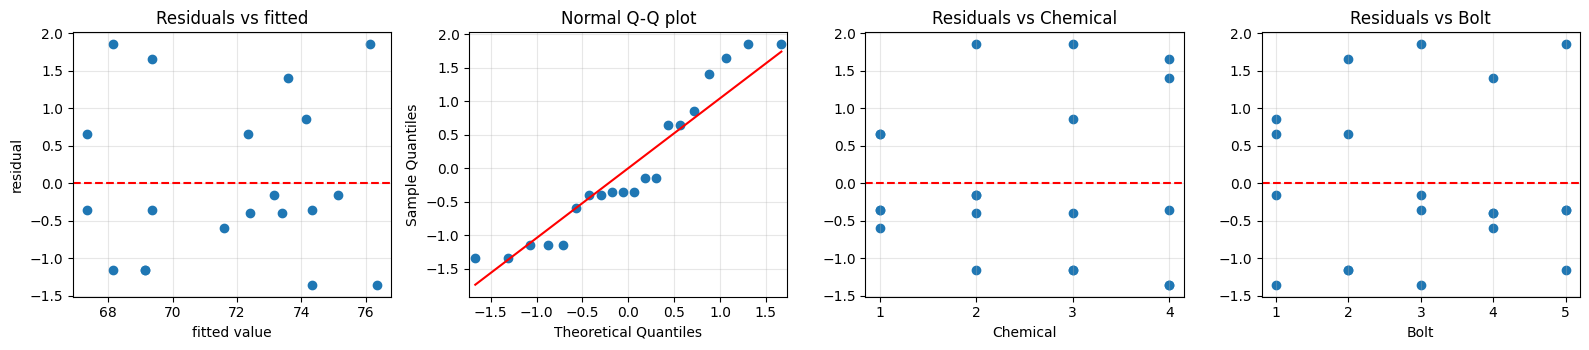

Shapiro-Wilk: W = 0.8996, P = 0.0405;  skewness = 0.49, excess kurtosis = -0.99
Levene (Brown-Forsythe) of the residuals across levels of Chemical: W = 0.889, P = 0.4677
Levene (Brown-Forsythe) of the residuals across levels of Bolt: W = 0.330, P = 0.8535
largest |standardized residual| = 1.77

Tukey's one-degree-of-freedom test for nonadditivity (row q_nonadd):


,df,sum_sq,mean_sq,F,PR(>F)
C(Chemical),3.0,12.9500,4.3167,2.1991,0.1456
C(Bolt),4.0,157.0000,39.2500,19.9960,0.0001
q_nonadd,1.0,0.2081,0.2081,0.1060,0.7508
Residual,11.0,21.5919,1.9629,NaN,NaN


In [26]:
# Q5: residual analysis and Tukey's test for nonadditivity
residual_plots(rcbd_cloth, cloth, ["Chemical", "Bolt"])
print("\nTukey's one-degree-of-freedom test for nonadditivity (row q_nonadd):")
display(tukey_nonadditivity(cloth, "Strength", "Chemical", "Bolt").round(4))


The residuals show no trend against the fitted values and a similar spread for every chemical and bolt (Levene $P = 0.47$ and
$0.85$); the largest standardized residuals (1.8) belong to chemical 3 on bolt 3 (78, the strongest reading) and chemical 2 on
bolt 5. The Shapiro-Wilk test is borderline ($W = 0.90$, $P = 0.041$): the normal probability plot has flat steps and a gap around
zero, a consequence of the integer readings and the small sample (skewness 0.5, excess kurtosis $-1.0$) rather than a departure
that would affect the $F$-test. Tukey's test gives $SS_N = 0.21$, $F_0 = 0.11$ on
(1, 11) df, $P = 0.75$: no evidence of a chemical $\times$ bolt interaction, the additive model is adequate.


**Conclusions (Problems 4.3 and 4.16)**

* **RCBD ANOVA.** Chemicals $F_0 = 2.38$ on (3, 12) df, $P = 0.12$: $H_0$ is **not rejected**, the chemical agents do not
  measurably change the cloth strength; bolts $F = 21.6$, $P < 10^{-4}$.
* **Estimates.** $\hat\mu = 71.75$, chemical effects between $-1.15$ and $0.85$, bolt effects between $-3.25$ and $3.75$.
* **Blocking.** Relative efficiency $R = 5.2$; a CRD would need about 26 bolts per chemical and would have given $P = 0.76$.
* **Assumptions.** Residual plots acceptable (normality borderline, $P = 0.041$); Tukey's nonadditivity test $P = 0.75$.


### Problems 5.4, 5.5 and 5.34: surface finish of a metal part

An engineer suspects that the surface finish of a metal part is influenced by the feed rate and the depth of cut. He selects
three feed rates (0.20, 0.25, 0.30 in/min) and four depths of cut (0.15, 0.18, 0.20, 0.25 in), and runs a factorial experiment
with three replicates.

In [27]:
finish = pd.read_csv(URL + "Chapter5_Pr02.csv", sep=";")
finish.columns = ["Depth", "Feed", "Finish"]
display(finish.pivot_table(index="Feed", columns="Depth", values="Finish", aggfunc=list))

Depth,0.15,0.18,0.20,0.25
Feed,,,,
0.20,"[74, 64, 60]","[79, 68, 73]","[82, 88, 92]","[99, 104, 96]"
0.25,"[92, 86, 88]","[98, 104, 88]","[99, 108, 95]","[104, 110, 99]"
0.30,"[99, 98, 102]","[104, 99, 95]","[108, 110, 99]","[114, 107, 111]"


**Question 1.** Draw an interaction plot. Then analyse the data and draw conclusions; report the $p$-values ($\alpha = 0.05$).

**Hypotheses.** Two-factor fixed-effects factorial with $a = 3$ feed rates, $b = 4$ depths of cut and $n = 3$ replicates
($N = 36$): $y_{ijk} = \mu + \tau_i + \beta_j + (\tau\beta)_{ij} + \varepsilon_{ijk}$, $\varepsilon_{ijk} \sim N(0, \sigma^2)$.
Tests of $H_0: (\tau\beta)_{ij} = 0$ ($F_{6,24}$), $H_0: \tau_i = 0$ ($F_{2,24}$) and $H_0: \beta_j = 0$ ($F_{3,24}$), each with
$F_0 = MS_{\text{effect}} / MS_E$ and $df_E = ab(n-1) = 24$.


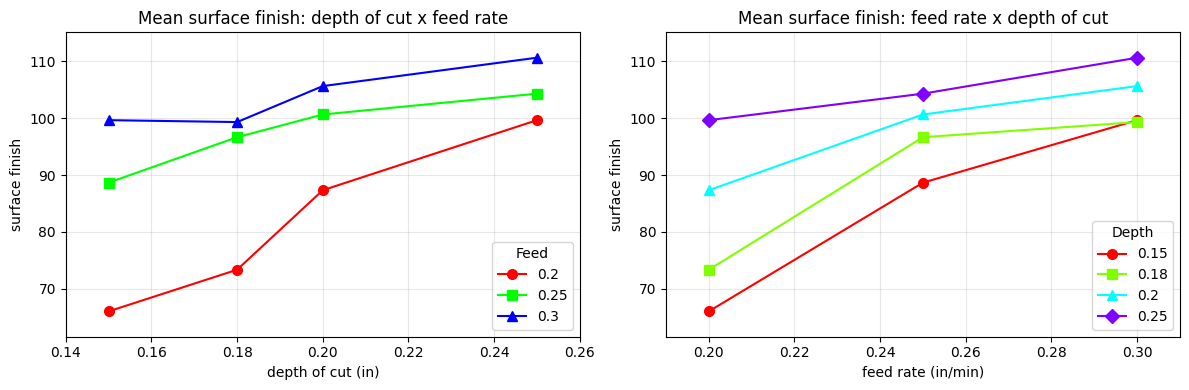

,sum_sq,df,F,PR(>F)
C(Feed),3160.5000,2.0,55.0184,1.09e-09
C(Depth),2125.1111,3.0,24.6628,1.65e-07
C(Feed):C(Depth),557.0556,6.0,3.2324,0.0180
Residual,689.3333,24.0,NaN,


MS_E = 28.7222 on 24 df
Cell means:


Depth,0.15,0.18,0.20,0.25
Feed,,,,
0.20,66.00,73.33,87.33,99.67
0.25,88.67,96.67,100.67,104.33
0.30,99.67,99.33,105.67,110.67


In [28]:
# Q1: interaction plots and two-factor ANOVA (alpha = 0.05)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
interaction_plot(finish["Depth"], finish["Feed"], finish["Finish"], ax=axes[0], markers=["o", "s", "^"], ms=7)
axes[0].set(title="Mean surface finish: depth of cut x feed rate", xlabel="depth of cut (in)", ylabel="surface finish")
interaction_plot(finish["Feed"], finish["Depth"], finish["Finish"], ax=axes[1], markers=["o", "s", "^", "D"], ms=7)
axes[1].set(title="Mean surface finish: feed rate x depth of cut", xlabel="feed rate (in/min)", ylabel="surface finish")
plt.tight_layout(); plt.show()

full_finish = smf.ols("Finish ~ C(Feed) * C(Depth)", data=finish).fit()
anova_finish = anova_report(full_finish)
print("Cell means:")
display(finish.pivot_table(index="Feed", columns="Depth", values="Finish", aggfunc="mean").round(2))


Feed rate: $F_0 = 55.0$ on (2, 24) df, $P = 1 \times 10^{-9}$; depth of cut: $F_0 = 24.7$ on (3, 24) df, $P = 2 \times 10^{-7}$;
interaction: $F_0 = 3.23$ on (6, 24) df, $P = 0.018$. All three are significant at $\alpha = 0.05$ ($MS_E = 28.7$ on 24 df).
The surface finish value increases with both feed rate and depth of cut, but not additively: at the lowest feed rate (0.20) the
depth effect is large (66 to 100), at the highest (0.30) it is small (100 to 111), and the lines of the interaction plot converge
at the largest depth. Because the interaction is significant, statements about the feed-rate effect are averages over the four
depths.


**Question 2.** Prepare appropriate residual plots and comment on the model's adequacy.

**Procedure.** Residuals of the full model against fitted values, normal probability plot and residuals by feed rate and depth.
With $n = 3$ observations per cell Levene's test across the 12 cells is meaningful here and is added.


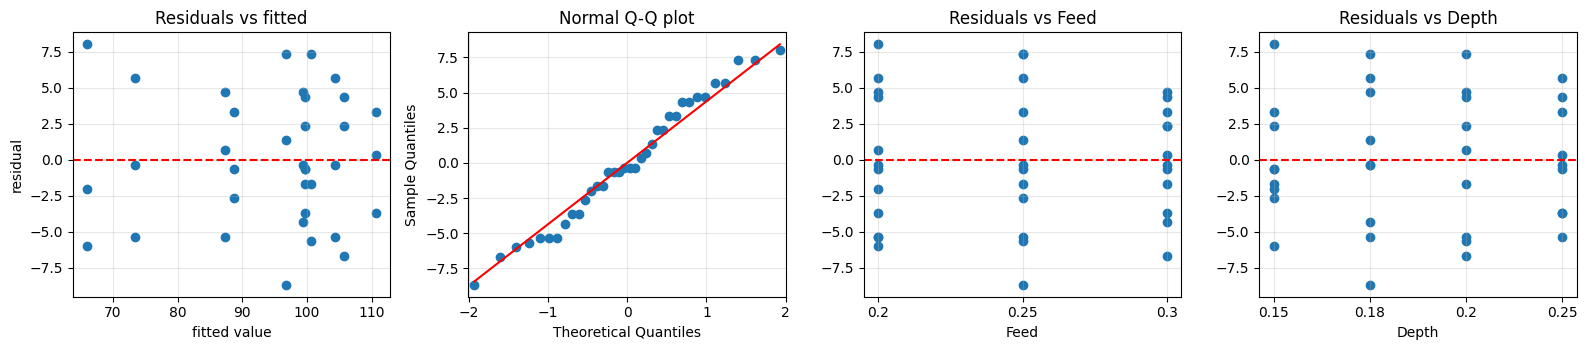

Shapiro-Wilk: W = 0.9705, P = 0.4397;  skewness = 0.04, excess kurtosis = -0.95
Levene (Brown-Forsythe) of the residuals across levels of Feed: W = 0.752, P = 0.4791
Levene (Brown-Forsythe) of the residuals across levels of Depth: W = 0.712, P = 0.5520
largest |standardized residual| = 1.98
Levene (Brown-Forsythe) across the 12 cells: W = 0.321, P = 0.9733


In [29]:
# Q2: residual analysis of the two-factor model
residual_plots(full_finish, finish, ["Feed", "Depth"])
cells_fin = [g["Finish"].to_numpy(dtype=float) for _, g in finish.groupby(["Feed", "Depth"])]
lv_fin = stats.levene(*cells_fin)
print(f"Levene (Brown-Forsythe) across the 12 cells: W = {lv_fin.statistic:.3f}, P = {lv_fin.pvalue:.4f}")


The residuals are spread evenly around zero at all fitted values and at every level of both factors (Levene across the 12 cells
$P = 0.97$, across feed rates $0.48$, across depths $0.55$); the normal probability plot is straight (Shapiro-Wilk $W = 0.97$,
$P = 0.44$) and the largest standardized residual is 2.0. The model is adequate.


**Question 3.** Obtain point estimates of the mean surface finish at each feed rate.

**Procedure.** The least-squares estimate of the mean response at feed rate $i$ is $\hat\mu_{i\cdot\cdot} = \bar y_{i\cdot\cdot}$,
the average of the $bn = 12$ observations at that feed rate, with standard error $\sqrt{MS_E / (bn)}$.


In [30]:
# Q3: point estimates of the mean surface finish at each feed rate
feed_means = finish.groupby("Feed")["Finish"].agg(n="count", mean="mean")
feed_means["se"] = np.sqrt(full_finish.mse_resid / feed_means["n"])
display(feed_means.round(3))
print("Tukey's HSD for feed rates (MS_E of the full model):")
display(tukey_from_model(full_finish, finish, "Feed", "Finish").round(4))


,n,mean,se
Feed,,,
0.20,12,81.583,1.547
0.25,12,97.583,1.547
0.30,12,103.833,1.547


Tukey's HSD for feed rates (MS_E of the full model):
MS_E = 28.72, df_E = 24, n per level = 12, HSD = 5.464


,pair,diff,lower,upper,p_adj,reject
0,0.25 - 0.2,16.00,10.5361,21.4639,0.0000,True
1,0.3 - 0.2,22.25,16.7861,27.7139,0.0000,True
2,0.3 - 0.25,6.25,0.7861,11.7139,0.0228,True


$\hat\mu_{0.20} = 81.6$, $\hat\mu_{0.25} = 97.6$ and $\hat\mu_{0.30} = 103.8$, each with standard error $\sqrt{28.7/12} = 1.55$.
Tukey's HSD ($T_{0.05} = 5.46$, 12 observations per level) separates all three feed rates.


**Question 4.** (Problem 5.5) Compute a 95 percent confidence interval for the mean difference in response for feed rates of 0.20 and 0.25 in/min.

**Procedure.** (Problem 5.5.) $\bar y_{1\cdot\cdot} - \bar y_{2\cdot\cdot} \pm t_{0.025,\,24}\sqrt{2MS_E/(bn)}$ with $MS_E = 28.7$ on
24 df from the full model and $bn = 12$ observations per feed rate.


In [31]:
# Q4 (Problem 5.5): 95% confidence interval for mu(0.20) - mu(0.25)
mse_fin, dfe_fin = full_finish.mse_resid, full_finish.df_resid
diff_fin = feed_means.loc[0.20, "mean"] - feed_means.loc[0.25, "mean"]
se_diff_fin = np.sqrt(2 * mse_fin / 12)
t_fin = stats.t.ppf(0.975, dfe_fin)
print(f"difference = {diff_fin:.3f}, se = {se_diff_fin:.3f}, t_0.025,{dfe_fin:.0f} = {t_fin:.3f}")
print(f"95% CI for mu(0.20) - mu(0.25): ({diff_fin - t_fin * se_diff_fin:.2f}, {diff_fin + t_fin * se_diff_fin:.2f})")
cm = finish.pivot_table(index="Feed", columns="Depth", values="Finish", aggfunc="mean")
print("Difference 0.20 - 0.25 at each depth of cut:", (cm.loc[0.20] - cm.loc[0.25]).round(2).to_dict())


difference = -16.000, se = 2.188, t_0.025,24 = 2.064
95% CI for mu(0.20) - mu(0.25): (-20.52, -11.48)
Difference 0.20 - 0.25 at each depth of cut: {0.15: -22.67, 0.18: -23.33, 0.2: -13.33, 0.25: -4.67}


The 95 % confidence interval for $\mu_{0.20} - \mu_{0.25}$ is $-16.0 \pm 2.064 \times 2.19 = (-20.5, -11.5)$: the slower feed
gives a surface finish value 11.5 to 20.5 units lower on average over the four depths of cut. Because of the interaction the
actual difference depends on the depth: about $-23$ at 0.15 and 0.18 in, $-13.3$ at 0.20 in and only $-4.7$ at 0.25 in.


**Question 5.** (Problem 5.34) Suppose that the experiment had been conducted in three blocks, with each replicate a block.
The observations in the data table are given in order: the first observation in each cell comes from the first replicate, and so on.
Reanalyse the data as a factorial experiment in blocks and estimate the variance component for blocks,
$\hat\sigma^2_{Block} = (MS_{Blocks} - MS_E)/(ab)$. Does blocking appear to be useful?

**Procedure.** (Problem 5.34.) Each replicate is a block: $y_{ijk} = \mu + \tau_i + \beta_j + (\tau\beta)_{ij} + \delta_k + \varepsilon_{ijk}$,
$k = 1, 2, 3$, no block $\times$ treatment interaction, $df_E = 24 - 2 = 22$. With random blocks
$E(MS_{\text{Blocks}}) = \sigma^2 + ab\,\sigma^2_{\text{Block}}$, so $\hat\sigma^2_{\text{Block}} = (MS_{\text{Blocks}} - MS_E)/(ab)$,
$ab = 12$. The block index is the order of the observation within each cell.


In [32]:
# Q5 (Problem 5.34): replicates as blocks
finish["Block"] = finish.groupby(["Feed", "Depth"]).cumcount() + 1
blk_finish = smf.ols("Finish ~ C(Block) + C(Feed) * C(Depth)", data=finish).fit()
anova_blkf = anova_report(blk_finish)
ms_blocks_fin = anova_blkf.loc["C(Block)", "sum_sq"] / anova_blkf.loc["C(Block)", "df"]
print("Block means:", finish.groupby("Block")["Finish"].mean().round(2).to_dict())
print(f"MS_Blocks = {ms_blocks_fin:.3f}, MS_E = {blk_finish.mse_resid:.3f}, "
      f"sigma^2_Block = ({ms_blocks_fin:.3f} - {blk_finish.mse_resid:.3f}) / 12 = {(ms_blocks_fin - blk_finish.mse_resid) / 12:.3f}")
print("\nP-values without and with the replicate blocks:")
display(pd.DataFrame({"P without blocks": anova_finish["PR(>F)"], "P with blocks": anova_blkf["PR(>F)"]}).dropna(how="all").round(4))


,sum_sq,df,F,PR(>F)
C(Block),146.0000,2.0,2.9558,0.0729
C(Feed),3160.5000,2.0,63.9856,6.77e-10
C(Depth),2125.1111,3.0,28.6825,8.70e-08
C(Feed):C(Depth),557.0556,6.0,3.7593,0.0100
Residual,543.3333,22.0,NaN,


MS_E = 24.6970 on 22 df
Block means: {1: 96.0, 2: 95.5, 3: 91.5}
MS_Blocks = 73.000, MS_E = 24.697, sigma^2_Block = (73.000 - 24.697) / 12 = 4.025

P-values without and with the replicate blocks:


,P without blocks,P with blocks
C(Block),NaN,0.0729
C(Depth),0.000,0.0000
C(Feed),0.000,0.0000
C(Feed):C(Depth),0.018,0.0100


Blocks: $F_0 = 2.96$ on (2, 22) df, $P = 0.073$, not significant at 0.05 but not negligible either: the third replicate runs
about 4 units lower (block means 96.0, 95.5, 91.5). The variance component estimate is
$\hat\sigma^2_{\text{Block}} = (73.0 - 24.7)/12 = 4.0$, about one sixth of the error variance. $MS_E$ falls from 28.7 to 24.7 at
the cost of 2 df, so every $F$ ratio increases (feed 55.0 to 64.0, depth 24.7 to 28.7, interaction 3.23 to 3.76 with $P$ from
0.018 to 0.010). Blocking appears mildly useful: it does not change the conclusions but sharpens them.


**Question 6.** Depth of cut is quantitative. Fit a model with linear and quadratic terms in depth (interacting with feed rate as a factor). Is a curvature in depth needed?

**Procedure.** Depth of cut is quantitative (0.15, 0.18, 0.20, 0.25 in). We fit linear and quadratic terms in depth, each
interacting with feed rate as a factor, and read the sequential (type I) sums of squares. With four levels a cubic term is also
possible: the difference between the full factorial (12 cell means) and the quadratic model is the lack of fit with 3 df, and
the sums of squares of the polynomial terms add up to $SS_{\text{Depth}}$ and $SS_{\text{Feed} \times \text{Depth}}$.


,df,sum_sq,mean_sq,F,PR(>F)
C(Feed),2.0,3160.5000,1580.2500,54.1249,0.0000
D,1.0,2042.2830,2042.2830,69.9499,0.0000
C(Feed):D,2.0,487.1164,243.5582,8.3421,0.0015
I(D ** 2),1.0,17.9704,17.9704,0.6155,0.4396
C(Feed):I(D ** 2),2.0,35.8283,17.9141,0.6136,0.5488
Residual,27.0,788.3019,29.1964,NaN,NaN


Quadratic terms (D^2 and Feed:D^2) jointly - linear-in-depth model vs quadratic model:


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,30.0,842.1006,0.0,NaN,NaN,NaN
1,27.0,788.3019,3.0,53.7987,0.6142,0.6117


Lack of fit of the quadratic model relative to the full factorial (cubic remainder, 3 df):


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,27.0,788.3019,0.0,NaN,NaN,NaN
1,24.0,689.3333,3.0,98.9686,1.1486,0.3497


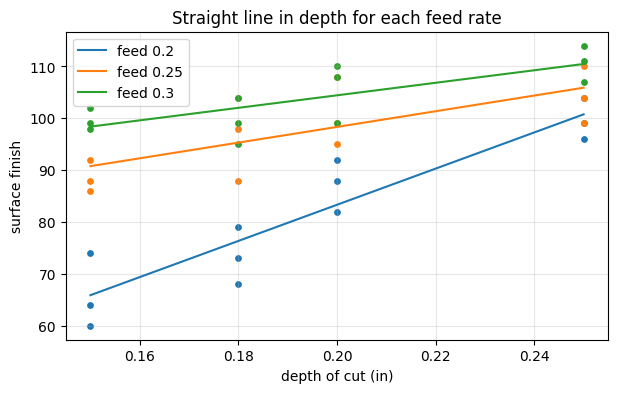

In [33]:
# Q6: depth of cut as a quantitative factor - linear and quadratic terms interacting with feed rate
finish["D"] = finish["Depth"].astype(float)
poly_finish = smf.ols("Finish ~ C(Feed) + D + I(D**2) + C(Feed):D + C(Feed):I(D**2)", data=finish).fit()
display(sm.stats.anova_lm(poly_finish, typ=1).round(4))
lin_finish = smf.ols("Finish ~ C(Feed) + D + C(Feed):D", data=finish).fit()
print("Quadratic terms (D^2 and Feed:D^2) jointly - linear-in-depth model vs quadratic model:")
display(sm.stats.anova_lm(lin_finish, poly_finish).round(4))
print("Lack of fit of the quadratic model relative to the full factorial (cubic remainder, 3 df):")
display(sm.stats.anova_lm(poly_finish, full_finish).round(4))

grid = np.linspace(0.15, 0.25, 50)
fig, ax = plt.subplots(figsize=(7, 4))
for feed, colour in zip(sorted(finish["Feed"].unique()), ["C0", "C1", "C2"]):
    ax.plot(grid, lin_finish.predict(pd.DataFrame({"Feed": feed, "D": grid})), color=colour, label=f"feed {feed}")
    sub = finish[finish["Feed"] == feed]
    ax.scatter(sub["D"], sub["Finish"], color=colour, s=15)
ax.set(xlabel="depth of cut (in)", ylabel="surface finish", title="Straight line in depth for each feed rate")
ax.legend(); plt.show()


The linear term in depth is dominant ($SS = 2042$, $P < 10^{-7}$) and its slope differs between feed rates (Feed:D,
$F_0 = 8.3$, $P = 0.0015$: steepest at feed 0.20, flattest at 0.30). The quadratic terms add almost nothing: $D^2$ $F_0 = 0.62$,
$P = 0.44$, Feed:$D^2$ $F_0 = 0.61$, $P = 0.55$, jointly $P = 0.61$; and the cubic remainder (lack of fit of the quadratic model)
has $P = 0.35$. **No curvature in depth is needed**: a straight line in depth for each feed rate (6 parameters instead of 12 cell
means) describes the data adequately. As a check, $2042 + 18 + 65 = 2125 = SS_{\text{Depth}}$ and $487 + 36 + 34 = 557 =
SS_{\text{Feed} \times \text{Depth}}$ of the factorial ANOVA.


**Conclusions (Problems 5.4, 5.5 and 5.34)**

* **ANOVA** ($MS_E = 28.7$ on 24 df): feed rate $F_0 = 55.0$, $P = 10^{-9}$; depth of cut $F_0 = 24.7$, $P = 2 \times 10^{-7}$;
  interaction $F_0 = 3.23$, $P = 0.018$: all **rejected**. Surface finish grows with feed rate and depth, the depth effect
  being strongest at the lowest feed rate.
* **Estimates.** Mean finish 81.6, 97.6 and 103.8 at feed rates 0.20, 0.25 and 0.30 (s.e. 1.55); 95 % CI for
  $\mu_{0.20} - \mu_{0.25}$: $(-20.5, -11.5)$.
* **Blocks** (5.34): $P = 0.073$, $\hat\sigma^2_{\text{Block}} = 4.0$; the $F$ ratios increase slightly, conclusions unchanged.
* **Depth as a quantitative factor.** Linear in depth with feed-specific slopes; no quadratic (or cubic) curvature needed
  ($P = 0.61$ and $0.35$).
* **Assumptions.** Residual plots and tests show no problems.


### Problem 5.15: two factors, one observation per cell

Analyse the following data from a two-factor factorial experiment and draw conclusions. Perform a test for nonadditivity
($\alpha = 0.05$).

| Row factor | Column 1 | Column 2 | Column 3 | Column 4 |
|---|---|---|---|---|
| 1 | 36 | 39 | 36 | 32 |
| 2 | 18 | 20 | 22 | 20 |
| 3 | 30 | 37 | 33 | 34 |

In [34]:
p515 = pd.read_csv(URL + "Chapter5_Pr13.csv", sep=";")
p515.pivot(index="Row", columns="Column", values="Data")

Column,1,2,3,4
Row,,,,
1,36,39,36,32
2,18,20,22,20
3,30,37,33,34


**Question 1.** Fit the additive model and test the main effects.

**Hypotheses.** Two factors with $a = 3$ rows, $b = 4$ columns and one observation per cell: with $n = 1$ the interaction cannot
be separated from the error, so the additive model $y_{ij} = \mu + \tau_i + \beta_j + \varepsilon_{ij}$ is fitted with
$(a-1)(b-1) = 6$ residual df. $H_0: \tau_i = 0$ ($F_0 \sim F_{2,6}$) and $H_0: \beta_j = 0$ ($F_0 \sim F_{3,6}$), $\alpha = 0.05$.


,sum_sq,df,F,PR(>F)
C(Row),580.5000,2.0,60.3988,0.0001
C(Column),28.9167,3.0,2.0058,0.2147
Residual,28.8333,6.0,NaN,


MS_E = 4.8056 on 6 df
Row means:    {1: 35.75, 2: 20.0, 3: 33.5}
Column means: {1: 28.0, 2: 32.0, 3: 30.33, 4: 28.67}


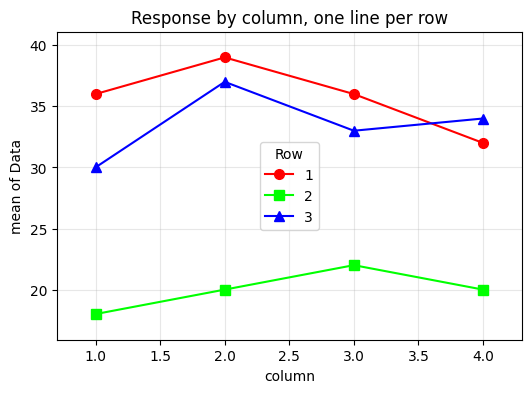

Tukey's HSD for rows (MS_E of the additive model, 4 observations per row):
MS_E = 4.806, df_E = 6, n per level = 4, HSD = 4.756


,pair,diff,lower,upper,p_adj,reject
0,2 - 1,-15.75,-20.5061,-10.9939,0.0001,True
1,3 - 1,-2.25,-7.0061,2.5061,0.3759,False
2,3 - 2,13.50,8.7439,18.2561,0.0003,True


In [35]:
# Q1: additive two-factor model (one observation per cell) and tests of the main effects
add_515 = smf.ols("Data ~ C(Row) + C(Column)", data=p515).fit()
anova_515 = anova_report(add_515)
print("Row means:   ", p515.groupby("Row")["Data"].mean().round(2).to_dict())
print("Column means:", p515.groupby("Column")["Data"].mean().round(2).to_dict())
fig, ax = plt.subplots(figsize=(6, 4))
interaction_plot(p515["Column"], p515["Row"], p515["Data"], ax=ax, markers=["o", "s", "^"], ms=7)
ax.set(title="Response by column, one line per row", xlabel="column"); plt.show()
print("Tukey's HSD for rows (MS_E of the additive model, 4 observations per row):")
display(tukey_from_model(add_515, p515, "Row", "Data").round(4))


Rows: $F_0 = 60.4$ on (2, 6) df, $P = 0.0001$: **reject $H_0$**, the row factor has a strong effect (row 2 mean 20.0 against
35.8 and 33.5 for rows 1 and 3; Tukey with $T_{0.05} = 4.76$: row 2 differs from both, rows 1 and 3 do not, difference 2.25).
Columns: $F_0 = 2.01$ on (3, 6) df, $P = 0.21$: not significant. $MS_E = 4.81$ on 6 df. The three lines in the plot are roughly
parallel except at column 4, where row 3 rises while rows 1 and 2 fall; whether that is interaction or noise is the subject of
Question 2.


**Question 2.** Perform Tukey's test for nonadditivity. What does the result mean for the conclusions of Question 1?

**Procedure.** Tukey's one-degree-of-freedom test: $H_0: \gamma = 0$ in $y_{ij} = \mu + \tau_i + \beta_j + \gamma\tau_i\beta_j + \varepsilon_{ij}$,
$F_0 = SS_N / \{SS_{\text{Error}} / [(a-1)(b-1) - 1]\} \sim F_{1,5}$ under $H_0$ (`tukey_nonadditivity()`), followed by the
residual plots of the additive model.


,df,sum_sq,mean_sq,F,PR(>F)
C(Row),2.0,580.5000,290.2500,57.3780,0.0004
C(Column),3.0,28.9167,9.6389,1.9055,0.2467
q_nonadd,1.0,3.5405,3.5405,0.6999,0.4410
Residual,5.0,25.2928,5.0586,NaN,NaN


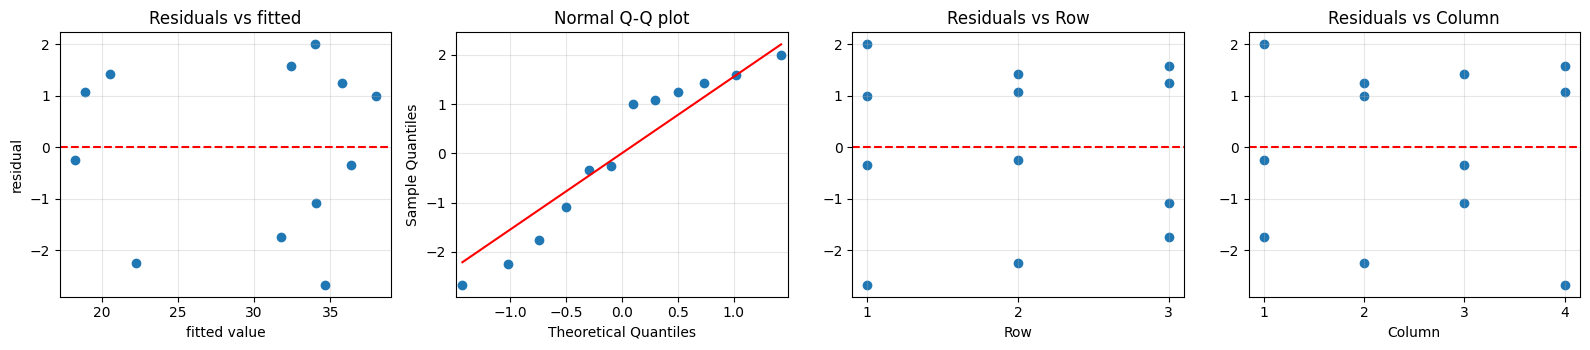

Shapiro-Wilk: W = 0.9063, P = 0.1911;  skewness = -0.40, excess kurtosis = -1.30
Levene (Brown-Forsythe) of the residuals across levels of Row: W = 0.087, P = 0.9176
Levene (Brown-Forsythe) of the residuals across levels of Column: W = 0.076, P = 0.9712
largest |standardized residual| = 1.72


In [36]:
# Q2: Tukey's test for nonadditivity (alpha = 0.05) and residual check
display(tukey_nonadditivity(p515, "Data", "Row", "Column").round(4))
residual_plots(add_515, p515, ["Row", "Column"])


$SS_N = 3.54$, $F_0 = 0.70$ on (1, 5) df, $P = 0.44$: no evidence of a row $\times$ column interaction of the multiplicative
form. The additive model is therefore tenable, its residual mean square (4.81 on 6 df) is a valid error term, and the conclusions
of Question 1 stand: the row factor matters, the column factor does not. Had the test rejected, the $F$-tests of Question 1 would
rest on an error term contaminated by interaction and a transformation of the response (or a replicated experiment) would be
needed. The residual plots show nothing unusual (Shapiro-Wilk $P = 0.19$, largest standardized residual 1.7).


**Conclusions (Problem 5.15)**

* **Additive model.** Row $F_0 = 60.4$ on (2, 6) df, $P = 0.0001$ (**rejected**; row 2 is about 14 to 16 units below rows 1 and 3,
  which do not differ); column $F_0 = 2.01$, $P = 0.21$ (not rejected).
* **Nonadditivity.** Tukey's test $F_0 = 0.70$ on (1, 5) df, $P = 0.44$: the additive model and its error term are justified, so
  the conclusions above hold.


## Assignment

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **4.21, 5.8 with 5.23, 5.18 and 5.20**.
  Start in class and finish at home.
* For every test state the hypotheses, report the test statistic, its $p$-value and your decision; for comparisons of means
  say which procedure and which error mean square you use; check the assumptions with residual plots; end each problem with
  a conclusion in one or two sentences.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex03_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 18 October 2026** (the next lecture is on 19 October).

### Problem 4.21: eye focus time

An industrial engineer is conducting an experiment on eye focus time. He is interested in the effect of the distance of the
object from the eye on the focus time. Four different distances are of interest. He has five subjects available for the
experiment. Because there may be differences among individuals, he decides to conduct the experiment in a randomized block design.

| Distance (ft) | Subject 1 | Subject 2 | Subject 3 | Subject 4 | Subject 5 |
|---|---|---|---|---|---|
| 4 | 10 | 6 | 6 | 6 | 6 |
| 6 | 7 | 6 | 6 | 1 | 6 |
| 8 | 5 | 3 | 3 | 2 | 5 |
| 10 | 6 | 4 | 4 | 2 | 3 |

In [37]:
focus_time = [[10, 6, 6, 6, 6],
              [7, 6, 6, 1, 6],
              [5, 3, 3, 2, 5],
              [6, 4, 4, 2, 3]]
distances = [4, 6, 8, 10]
focus = pd.DataFrame([(distances[d], s + 1, focus_time[d][s]) for d in range(4) for s in range(5)],
                     columns=["Distance", "Subject", "Time"])
focus.pivot(index="Distance", columns="Subject", values="Time")

Subject,1,2,3,4,5
Distance,,,,,
4,10,6,6,6,6
6,7,6,6,1,6
8,5,3,3,2,5
10,6,4,4,2,3


**Question 1.** Analyse the data ($\alpha = 0.05$) and draw appropriate conclusions.

**Hypotheses.** Randomized complete block design with $a = 4$ distances (treatments) and $b = 5$ subjects (blocks), one
observation per cell ($N = 20$):

$$y_{ij} = \mu + \tau_i + \beta_j + \varepsilon_{ij}, \qquad \sum_i \tau_i = \sum_j \beta_j = 0, \qquad \varepsilon_{ij} \sim N(0, \sigma^2) \text{ i.i.d.}$$

$$H_0:\ \tau_1 = \tau_2 = \tau_3 = \tau_4 = 0 \qquad\text{vs.}\qquad H_1:\ \tau_i \ne 0 \text{ for at least one } i.$$

Test statistic $F_0 = MS_{\text{Distance}} / MS_E \sim F_{a-1,\,(a-1)(b-1)} = F_{3,12}$ under $H_0$; reject at $\alpha = 0.05$
if $F_0 > F_{0.05;\,3,12} = 3.49$, i.e. if $P < 0.05$. The subjects are blocks: their $F$ ratio is reported as a descriptive
measure of how much block-to-block variation was removed, not as a formal test (randomization was restricted to within subjects).


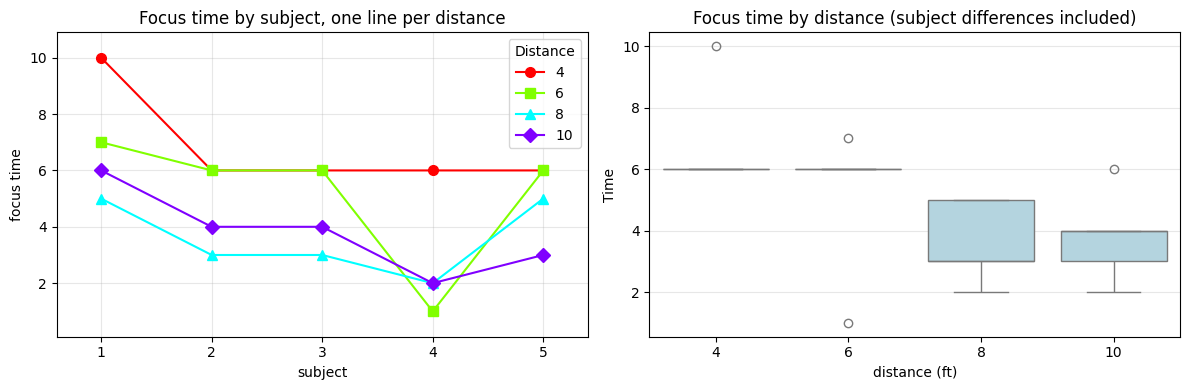

,sum_sq,df,F,PR(>F)
C(Distance),32.95,3.0,8.6144,0.0025
C(Subject),36.30,4.0,7.1176,0.0035
Residual,15.30,12.0,NaN,


MS_E = 1.2750 on 12 df
F_0 = 8.614 on (3, 12) df, critical value F_0.05;3,12 = 3.490, P = 0.0025
Mean focus time by distance: {4: 6.8, 6: 5.2, 8: 3.6, 10: 3.8}
Mean focus time by subject:  {1: 7.0, 2: 4.75, 3: 4.75, 4: 2.75, 5: 5.0}


In [38]:
# Q1: plots and the RCBD ANOVA (alpha = 0.05)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
interaction_plot(focus["Subject"], focus["Distance"], focus["Time"], ax=axes[0], markers=["o", "s", "^", "D"], ms=7)
axes[0].set(title="Focus time by subject, one line per distance", xlabel="subject", ylabel="focus time")
sns.boxplot(data=focus, x="Distance", y="Time", ax=axes[1], color="lightblue")
axes[1].set(title="Focus time by distance (subject differences included)", xlabel="distance (ft)")
plt.tight_layout(); plt.show()

rcbd_focus = smf.ols("Time ~ C(Distance) + C(Subject)", data=focus).fit()
anova_focus = anova_report(rcbd_focus)
f0, p0 = anova_focus.loc["C(Distance)", "F"], anova_focus.loc["C(Distance)", "PR(>F)"]
print(f"F_0 = {f0:.3f} on (3, 12) df, critical value F_0.05;3,12 = {stats.f.ppf(0.95, 3, 12):.3f}, P = {p0:.4f}")
print("Mean focus time by distance:", focus.groupby("Distance")["Time"].mean().round(2).to_dict())
print("Mean focus time by subject: ", focus.groupby("Subject")["Time"].mean().round(2).to_dict())


$F_0 = 8.61$ on (3, 12) df, $P = 0.0025 < 0.05$: we **reject $H_0$**, the distance of the object affects the mean focus time.
The mean time falls from 6.8 at 4 ft to 5.2 at 6 ft and about 3.7 at 8 and 10 ft, so focusing is slowest for the nearest object
and the curve flattens beyond 8 ft. The subjects differ a lot as well ($F = 7.12$, $P = 0.0035$; subject 1 is slow, subject 4
fast), which is exactly the variability that blocking removed from the error term ($MS_E = 1.275$ on 12 df). In the left plot the
four lines move roughly in parallel across subjects, as the additive model assumes.


**Question 2.** Which distances differ? Use Tukey's HSD with the error mean square of the RCBD.

**Procedure.** Tukey's HSD with the error mean square of the RCBD, $MS_E = 1.275$ on 12 df, and $n = b = 5$ observations per
distance:

$$T_{0.05} = q_{0.05}(4, 12)\,\sqrt{MS_E / b}, \qquad \text{declare } \mu_i \ne \mu_k \text{ if } |\bar y_{i\cdot} - \bar y_{k\cdot}| > T_{0.05}.$$

`tukey_from_model()` takes $MS_E$ and $df_E$ from the fitted RCBD. (`pairwise_tukeyhsd()` would refit a one-way model with
$MS_E = 3.225$ on 16 df, i.e. with the subject variation left in the error; its output is shown last as a warning.) Fisher's LSD,
$t_{0.025,12}\sqrt{2MS_E/b}$, is added for comparison only.


In [39]:
# Q2: Tukey's HSD with MS_E and df_E of the RCBD (alpha = 0.05); Fisher's LSD for comparison
mse_f, dfe_f, b_f = rcbd_focus.mse_resid, rcbd_focus.df_resid, focus["Subject"].nunique()
q_crit = stats.studentized_range.ppf(0.95, 4, dfe_f)
lsd_f = stats.t.ppf(0.975, dfe_f) * np.sqrt(2 * mse_f / b_f)
print(f"q_0.05(4, {dfe_f:.0f}) = {q_crit:.3f}, HSD = {q_crit * np.sqrt(mse_f / b_f):.3f}, LSD = {lsd_f:.3f}")
tukey_focus = tukey_from_model(rcbd_focus, focus, "Distance", "Time")
tukey_focus["|diff| > LSD"] = tukey_focus["diff"].abs() > lsd_f
display(tukey_focus.round(4))
print("WRONG for an RCBD - pairwise_tukeyhsd() ignores the subjects:")
print(pairwise_tukeyhsd(focus["Time"], focus["Distance"]))


q_0.05(4, 12) = 4.199, HSD = 2.120, LSD = 1.556
MS_E = 1.275, df_E = 12, n per level = 5, HSD = 2.12


,pair,diff,lower,upper,p_adj,reject,|diff| > LSD
0,6 - 4,-1.6,-3.7202,0.5202,0.1675,False,True
1,8 - 4,-3.2,-5.3202,-1.0798,0.0036,True,True
2,10 - 4,-3.0,-5.1202,-0.8798,0.0058,True,True
3,8 - 6,-1.6,-3.7202,0.5202,0.1675,False,True
4,10 - 6,-1.4,-3.5202,0.7202,0.2554,False,False
5,10 - 8,0.2,-1.9202,2.3202,0.9919,False,False


WRONG for an RCBD - pairwise_tukeyhsd() ignores the subjects:
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     4      6     -1.6 0.5121 -4.8495 1.6495  False
     4      8     -3.2 0.0543 -6.4495 0.0495  False
     4     10     -3.0 0.0757 -6.2495 0.2495  False
     6      8     -1.6 0.5121 -4.8495 1.6495  False
     6     10     -1.4 0.6161 -4.6495 1.8495  False
     8     10      0.2  0.998 -3.0495 3.4495  False
---------------------------------------------------


With $T_{0.05} = 2.12$ only the comparisons with the shortest distance are significant: 4 ft vs 8 ft (difference 3.2, adjusted
$P = 0.004$) and 4 ft vs 10 ft (3.0, $P = 0.006$). The differences 4 vs 6 ft (1.6), 6 vs 8 ft (1.6), 6 vs 10 ft (1.4) and
8 vs 10 ft (0.2) are not significant, so the Tukey grouping is $\{4\}$ and $\{6, 8, 10\}$ with 6 ft overlapping both: 4 ft gives
the longest focus time, 8 and 10 ft the shortest. The less conservative LSD (1.56) would additionally separate 4 from 6 ft and
6 from 8 ft, but it does not control the family-wise error rate. The one-way Tukey test with the subjects ignored
($MS_E = 3.225$, $T_{0.05} = 3.25$) finds no significant difference at all (4 vs 8 ft only reaches $P = 0.054$).


**Question 3.** Analyse the residuals and perform Tukey's test for nonadditivity.

**Procedure.** Residuals $e_{ij} = y_{ij} - \hat y_{ij}$ of the RCBD, with $\hat y_{ij} = \bar y_{i\cdot} + \bar y_{\cdot j} - \bar y_{\cdot\cdot}$,
plotted against the fitted values, on a normal probability plot and against both factors. Tukey's one-degree-of-freedom test
for nonadditivity tests $H_0: \gamma = 0$ in the model $y_{ij} = \mu + \tau_i + \beta_j + \gamma\,\tau_i\beta_j + \varepsilon_{ij}$
(`tukey_nonadditivity()`: the covariate $q_{ij} = \hat\tau_i\hat\beta_j$ is added to the additive model, its sequential sum of
squares is $SS_N$ with 1 df, and $F_0 = SS_N / \{SS_{\text{Error}} / [(a-1)(b-1) - 1]\} \sim F_{1,11}$ under $H_0$).


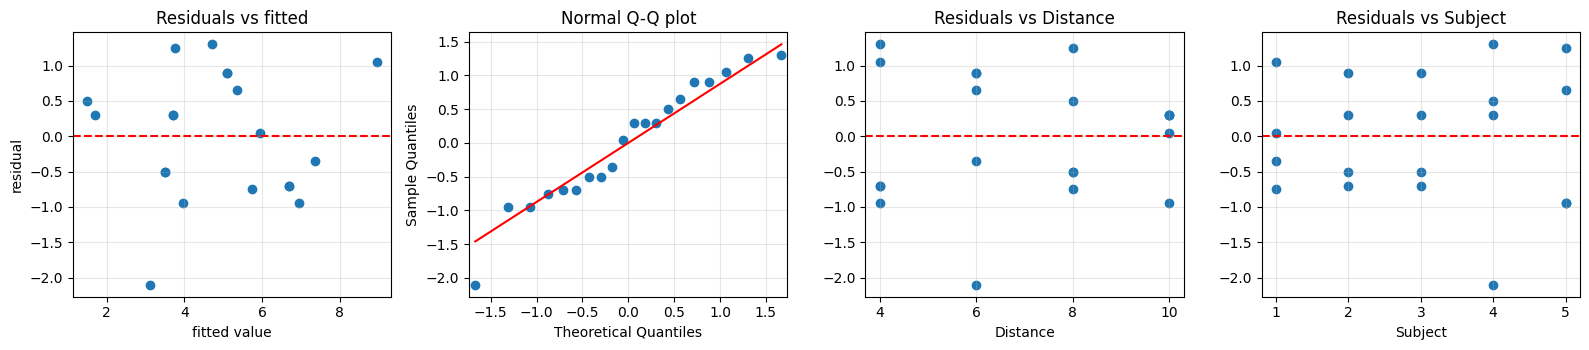

Shapiro-Wilk: W = 0.9498, P = 0.3634;  skewness = -0.38, excess kurtosis = -0.43
Levene (Brown-Forsythe) of the residuals across levels of Distance: W = 0.399, P = 0.7558
Levene (Brown-Forsythe) of the residuals across levels of Subject: W = 0.408, P = 0.8002
largest |standardized residual| = 2.40
Observation with the largest standardized residual: {'Distance': 6.0, 'Subject': 4.0, 'Time': 1.0, 'resid': -2.1, 'std_resid': -2.4}

Tukey's one-degree-of-freedom test for nonadditivity (row q_nonadd):


,df,sum_sq,mean_sq,F,PR(>F)
C(Distance),3.0,32.9500,10.9833,8.0410,0.0041
C(Subject),4.0,36.3000,9.0750,6.6439,0.0057
q_nonadd,1.0,0.2749,0.2749,0.2013,0.6624
Residual,11.0,15.0251,1.3659,NaN,NaN


In [40]:
# Q3: residual analysis and Tukey's test for nonadditivity
residual_plots(rcbd_focus, focus, ["Distance", "Subject"])
std_res = rcbd_focus.get_influence().resid_studentized_internal
worst = focus.assign(resid=rcbd_focus.resid.round(3), std_resid=std_res.round(2)).iloc[np.abs(std_res).argmax()]
print("Observation with the largest standardized residual:", worst.to_dict())
print("\nTukey's one-degree-of-freedom test for nonadditivity (row q_nonadd):")
nonadd_focus = tukey_nonadditivity(focus, "Time", "Distance", "Subject")
display(nonadd_focus.round(4))


The residuals show no funnel against the fitted values and no systematic pattern against distance or subject; the normal
probability plot is reasonably straight and the Shapiro-Wilk test does not reject normality ($W = 0.95$, $P = 0.36$). The
largest residual ($-2.1$, standardized $-2.4$) belongs to subject 4 at 6 ft, whose focus time of 1 is far below the other
readings of that subject; it does not exceed the usual $\pm 3$ outlier limit, but it is the single most influential value in the data
set and the only point off the line of the normal plot. Tukey's test gives $SS_N = 0.27$, $F_0 = 0.20$ on (1, 11) df, $P = 0.66$: there is no evidence of a distance $\times$ subject
interaction of the multiplicative form, so the additive RCBD model (and the use of $MS_E$ as the error) is adequate.


**Question 4.** Reanalyse the data ignoring the subjects (completely randomized design) and compute the relative efficiency of the RCBD. Was blocking on subjects worthwhile?

**Procedure.** The same data are fitted as a completely randomized design, $y_{ij} = \mu + \tau_i + \varepsilon_{ij}$, so that
the subject variation goes into the error term ($df_E = N - a = 16$). The relative efficiency of the RCBD with respect to the
CRD (Montgomery, Supplemental Material S4.1; `relative_efficiency()` from Section 1 of this notebook) is

$$R = \frac{(df_b+1)(df_r+3)}{(df_b+3)(df_r+1)}\,\frac{\hat\sigma_r^2}{\hat\sigma_b^2}, \qquad
\hat\sigma_r^2 = \frac{(b-1)MS_{\text{Blocks}} + b(a-1)MS_E}{ab-1}, \qquad \hat\sigma_b^2 = MS_E,$$

with $df_b = (a-1)(b-1) = 12$ and $df_r = a(b-1) = 16$. $R$ is the number of observations per treatment a CRD would need to
match the precision of one observation per treatment in the RCBD.


In [41]:
# Q4: CRD analysis (subjects ignored) and the relative efficiency of the RCBD
crd_focus = smf.ols("Time ~ C(Distance)", data=focus).fit()
print("CRD: subjects ignored")
anova_crd = anova_report(crd_focus)
print(f"MS_E RCBD = {rcbd_focus.mse_resid:.4f} (12 df), MS_E CRD = {crd_focus.mse_resid:.4f} (16 df), naive ratio = {crd_focus.mse_resid / rcbd_focus.mse_resid:.2f}")
ratio_f, R_f = relative_efficiency(rcbd_focus, "C(Subject)", a=4, b=5)
ms_blocks_f = anova_focus.loc["C(Subject)", "sum_sq"] / anova_focus.loc["C(Subject)", "df"]
sigma2_r = ((5 - 1) * ms_blocks_f + 5 * (4 - 1) * rcbd_focus.mse_resid) / (4 * 5 - 1)
print(f"MS_Blocks = {ms_blocks_f:.4f}, sigma_r^2 (error variance of an equivalent CRD) = {sigma2_r:.4f}")
print(f"variance ratio sigma_r^2 / MS_E = {ratio_f:.3f}, relative efficiency R = {R_f:.3f}")
print(f"-> a CRD would need about {R_f * 5:.1f} observations per distance instead of 5 for the same precision")


CRD: subjects ignored


,sum_sq,df,F,PR(>F)
C(Distance),32.95,3.0,3.4057,0.0434
Residual,51.60,16.0,NaN,


MS_E = 3.2250 on 16 df
MS_E RCBD = 1.2750 (12 df), MS_E CRD = 3.2250 (16 df), naive ratio = 2.53
MS_Blocks = 9.0750, sigma_r^2 (error variance of an equivalent CRD) = 2.9171
variance ratio sigma_r^2 / MS_E = 2.288, relative efficiency R = 2.216
-> a CRD would need about 11.1 observations per distance instead of 5 for the same precision


Ignoring the subjects moves $SS_{\text{Subject}} = 36.3$ into the error: $MS_E$ rises from 1.275 to 3.225 and $F_0$ for distance
drops from 8.61 to 3.41 ($P = 0.043$), still significant at $\alpha = 0.05$ but only just. The naive ratio of the error mean
squares (2.5) overstates the benefit, because a real CRD would use 20 different people; the estimated error variance of such a
CRD is $\hat\sigma_r^2 = 2.92$ and the relative efficiency is $R = 2.22$ after the degrees-of-freedom correction. A completely
randomized design would thus need about 2.2 times as many observations per distance, 11 instead of 5, to estimate the distance
means as precisely. Blocking on subjects cost 4 error df and was clearly worthwhile.


**Question 5.** Assume that the subjects are a random sample of people. Estimate the block variance component $\hat\sigma^2_\beta = (MS_{Blocks} - MS_E)/a$.

**Procedure.** If the five subjects are a random sample of people, $\beta_j \sim N(0, \sigma_\beta^2)$ independently of
$\varepsilon_{ij}$. Then $E(MS_{\text{Blocks}}) = \sigma^2 + a\,\sigma_\beta^2$ and $E(MS_E) = \sigma^2$, so the
analysis-of-variance (method of moments) estimators are

$$\hat\sigma^2 = MS_E, \qquad \hat\sigma_\beta^2 = \frac{MS_{\text{Blocks}} - MS_E}{a}$$

(set to zero if negative). The test for distances is unchanged: $F_0 = MS_{\text{Distance}} / MS_E$ as in Question 1.


In [42]:
# Q5: subjects as random blocks - variance components
a_f = focus["Distance"].nunique()
sigma2_e = rcbd_focus.mse_resid
sigma2_beta = max(0.0, (ms_blocks_f - sigma2_e) / a_f)
print(f"MS_Blocks = {ms_blocks_f:.4f}, MS_E = {sigma2_e:.4f}, a = {a_f}")
print(f"sigma^2_beta (subjects) = ({ms_blocks_f:.4f} - {sigma2_e:.4f}) / {a_f} = {sigma2_beta:.4f}")
print(f"sigma^2 (error)         = {sigma2_e:.4f}")
print(f"ratio sigma^2_beta / sigma^2 = {sigma2_beta / sigma2_e:.2f}; share of the variance of a single reading due to subjects = {sigma2_beta / (sigma2_beta + sigma2_e):.2f}")
print(f"The F-test for distances is unchanged: F_0 = {f0:.3f}, P = {p0:.4f}")


MS_Blocks = 9.0750, MS_E = 1.2750, a = 4
sigma^2_beta (subjects) = (9.0750 - 1.2750) / 4 = 1.9500
sigma^2 (error)         = 1.2750
ratio sigma^2_beta / sigma^2 = 1.53; share of the variance of a single reading due to subjects = 0.60
The F-test for distances is unchanged: F_0 = 8.614, P = 0.0025


$\hat\sigma_\beta^2 = (9.075 - 1.275)/4 = 1.95$ against $\hat\sigma^2 = 1.275$: the person-to-person variance is about 1.5 times
the within-person error variance and accounts for roughly 60 % of the variance of a single focus-time reading. This confirms the
picture of Question 4: subjects are a major source of variability, and any future study of focus time should keep them as blocks
(repeated measurements on the same people). The treatment test and the comparisons of Questions 1 and 2 are unaffected by
treating the blocks as random.


**Conclusions (Problem 4.21)**

* **RCBD ANOVA.** $F_0 = 8.61$ on (3, 12) df, $P = 0.0025 < 0.05$: we **reject $H_0$**, the distance of the object affects the
  mean eye focus time ($MS_E = 1.275$ on 12 df).
* **Tukey's HSD** with the RCBD error ($T_{0.05} = 2.12$): 4 ft (mean 6.8) is slower than 8 ft (3.6) and 10 ft (3.8); 6 ft (5.2)
  cannot be separated from either group. Focus time decreases with distance and levels off beyond about 8 ft.
* **Assumptions.** No pattern in the residuals, Shapiro-Wilk $P = 0.36$, Tukey's nonadditivity test $P = 0.66$: the additive model
  is adequate. One low reading (subject 4 at 6 ft) is noticeable but not an outlier.
* **Blocking.** As a CRD the effect would be borderline ($P = 0.043$); the relative efficiency $R = 2.2$ and the subject variance
  component $\hat\sigma_\beta^2 = 1.95$ ($1.5\,\hat\sigma^2$) show that blocking on subjects was worthwhile.


### Problems 5.8, 5.23 and 5.36: breaking strength of a synthetic fibre

The factors that influence the breaking strength of a synthetic fibre are being studied. Four production machines and three
operators are chosen and a factorial experiment is run using fibre from the same production batch; two replicates.

In [43]:
fibre = pd.read_csv(URL + "Chapter5_Pr06.csv", sep=";")
display(fibre.pivot_table(index="Operator", columns="Machine", values="Strength", aggfunc=list))

Machine,1,2,3,4
Operator,,,,
1,"[109, 110]","[110, 115]","[108, 109]","[110, 108]"
2,"[110, 112]","[110, 111]","[111, 109]","[114, 112]"
3,"[116, 114]","[112, 115]","[114, 119]","[120, 117]"


**Question 1.** Draw an interaction plot, analyse the data and draw conclusions ($\alpha = 0.05$).

**Hypotheses.** Two-factor fixed-effects factorial with $a = 3$ operators, $b = 4$ machines and $n = 2$ replicates ($N = 24$):

$$y_{ijk} = \mu + \tau_i + \beta_j + (\tau\beta)_{ij} + \varepsilon_{ijk}, \qquad \varepsilon_{ijk} \sim N(0, \sigma^2) \text{ i.i.d.}$$

Three tests, each with $F_0 = MS_{\text{effect}} / MS_E$ and $df_E = ab(n-1) = 12$:

* interaction: $H_0: (\tau\beta)_{ij} = 0$ for all $i, j$, $F_0 \sim F_{6,12}$;
* operators: $H_0: \tau_1 = \tau_2 = \tau_3 = 0$, $F_0 \sim F_{2,12}$;
* machines: $H_0: \beta_1 = \dots = \beta_4 = 0$, $F_0 \sim F_{3,12}$.

The interaction is interpreted first; if it is not significant the main effects can be read from the marginal means.
A significant main effect is followed by Tukey's HSD with $MS_E$ and $df_E$ of the full two-factor model.


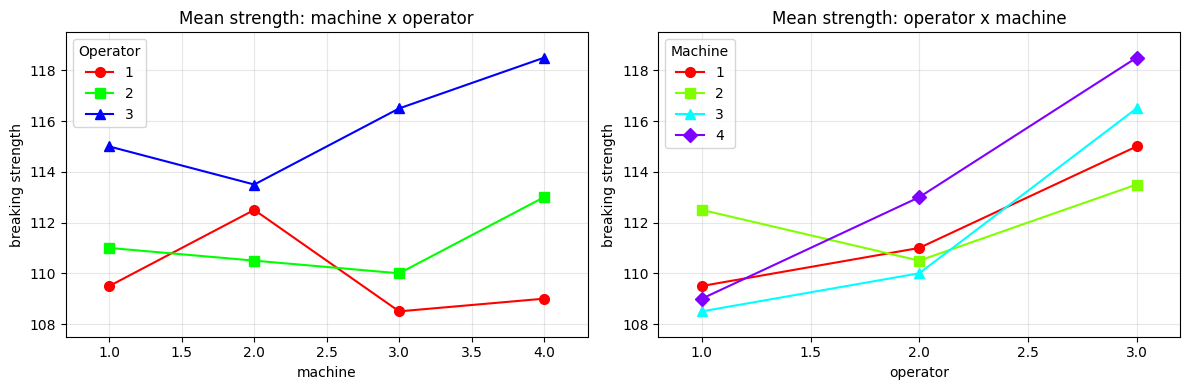

,sum_sq,df,F,PR(>F)
C(Operator),160.3333,2.0,21.1429,0.0001
C(Machine),12.4583,3.0,1.0952,0.3888
C(Operator):C(Machine),44.6667,6.0,1.9634,0.1507
Residual,45.5000,12.0,NaN,


MS_E = 3.7917 on 12 df
Operator means: {1: 109.88, 2: 111.12, 3: 115.88}
Machine means:  {1: 111.83, 2: 112.17, 3: 111.67, 4: 113.5}

Tukey's HSD for operators (MS_E and df_E of the full two-factor model, bn = 8 observations per operator):
MS_E = 3.792, df_E = 12, n per level = 8, HSD = 2.597


,pair,diff,lower,upper,p_adj,reject
0,2 - 1,1.25,-1.3475,3.8475,0.4302,False
1,3 - 1,6.00,3.4025,8.5975,0.0001,True
2,3 - 2,4.75,2.1525,7.3475,0.0010,True


In [44]:
# Q1: interaction plots, two-factor ANOVA (alpha = 0.05) and comparisons for the significant main effect
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
interaction_plot(fibre["Machine"], fibre["Operator"], fibre["Strength"], ax=axes[0], markers=["o", "s", "^"], ms=7)
axes[0].set(title="Mean strength: machine x operator", xlabel="machine", ylabel="breaking strength")
interaction_plot(fibre["Operator"], fibre["Machine"], fibre["Strength"], ax=axes[1], markers=["o", "s", "^", "D"], ms=7)
axes[1].set(title="Mean strength: operator x machine", xlabel="operator", ylabel="breaking strength")
plt.tight_layout(); plt.show()

full_fibre = smf.ols("Strength ~ C(Operator) * C(Machine)", data=fibre).fit()
anova_fibre = anova_report(full_fibre)
print("Operator means:", fibre.groupby("Operator")["Strength"].mean().round(2).to_dict())
print("Machine means: ", fibre.groupby("Machine")["Strength"].mean().round(2).to_dict())
print("\nTukey's HSD for operators (MS_E and df_E of the full two-factor model, bn = 8 observations per operator):")
display(tukey_from_model(full_fibre, fibre, "Operator", "Strength").round(4))


* Interaction: $F_0 = 1.96$ on (6, 12) df, $P = 0.15$: not significant, the operator effect is the same on every machine.
  The lines in the plots are roughly parallel; the bumps (operator 1 highest on machine 2, operator 3 lowest on machine 2) are
  within the noise.
* Operators: $F_0 = 21.14$ on (2, 12) df, $P = 0.0001$: **reject $H_0$**, the operators differ.
* Machines: $F_0 = 1.10$ on (3, 12) df, $P = 0.39$: not significant, the four machines give the same mean strength
  (111.7 to 113.5).

Tukey's HSD ($MS_E = 3.79$ on 12 df, $T_{0.05} = 2.60$): operator 3 (mean 115.9) produces stronger fibre than operator 1
(109.9, adjusted $P = 0.0001$) and operator 2 (111.1, $P = 0.001$); operators 1 and 2 do not differ (1.25, $P = 0.43$).


**Question 2.** Prepare appropriate residual plots and comment on the model's adequacy.

**Procedure.** Residuals of the full model (within each cell $e_{ijk} = y_{ijk} - \bar y_{ij\cdot}$, so with $n = 2$ they come in
pairs $\pm r_{ij}$) against the fitted values, on a normal probability plot and against operator and machine; Shapiro-Wilk test
and Levene's test of the residual spread across operators and across machines.


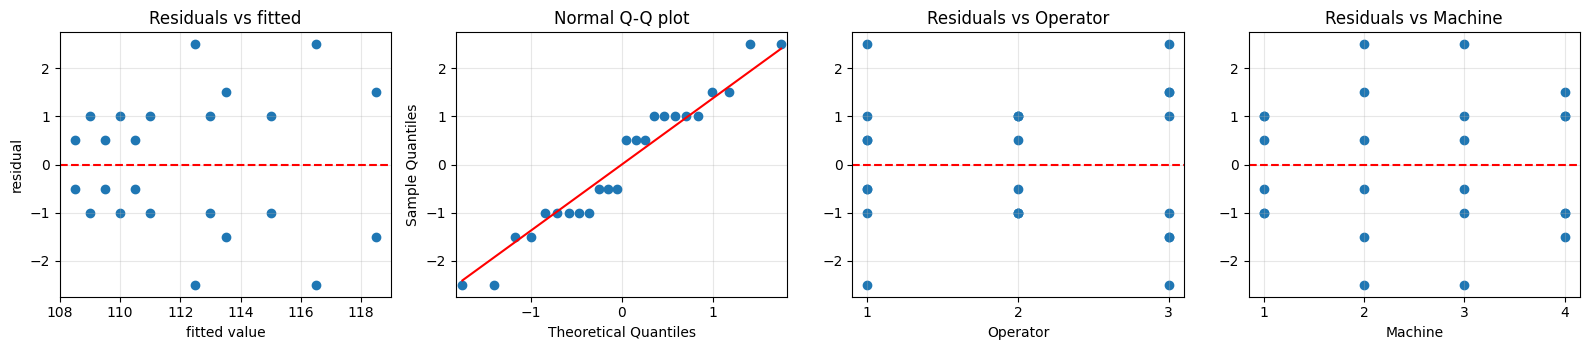

Shapiro-Wilk: W = 0.9493, P = 0.2611;  skewness = 0.00, excess kurtosis = -0.83
Levene (Brown-Forsythe) of the residuals across levels of Operator: W = 3.015, P = 0.0706
Levene (Brown-Forsythe) of the residuals across levels of Machine: W = 1.080, P = 0.3800
largest |standardized residual| = 1.82
Cell standard deviations (n = 2):


Machine,1,2,3,4
Operator,,,,
1,0.71,3.54,0.71,1.41
2,1.41,0.71,1.41,1.41
3,1.41,2.12,3.54,2.12


In [45]:
# Q2: residual analysis of the two-factor model
residual_plots(full_fibre, fibre, ["Operator", "Machine"])
print("Cell standard deviations (n = 2):")
display(fibre.pivot_table(index="Operator", columns="Machine", values="Strength", aggfunc="std").round(2))


The residuals lie in a horizontal band of constant width against the fitted values and against both factors, the normal
probability plot is straight ($W = 0.95$, $P = 0.26$) and Levene's test does not reject equal spread across machines ($P = 0.38$) or
across operators ($P = 0.07$; operator 2's residuals are somewhat tighter than those of operators 1 and 3). The largest standardized residuals (1.8) come from the two cells with the widest pairs (operator 1 on machine 2,
operator 3 on machine 3), and the cell standard deviations range from 0.7 to 3.5 with only two observations each. The model is
adequate.


**Question 3.** (Problems 5.23 and 5.36) Analyse the data assuming that the two replicates are blocks (the first observation in each cell
comes from the first replicate). Estimate the variance component for blocks, $\hat\sigma^2_{Block} = (MS_{Blocks} - MS_E)/(ab)$.
Does blocking change the conclusions?

**Procedure.** (Problems 5.23 and 5.36.) If each replicate was run as a complete block (for example on a different day), the model
becomes

$$y_{ijk} = \mu + \tau_i + \beta_j + (\tau\beta)_{ij} + \delta_k + \varepsilon_{ijk}, \qquad k = 1, 2 \text{ (blocks)},$$

with no block $\times$ treatment interaction; the block effect takes $n - 1 = 1$ df from the error ($df_E = 11$). Treating the
blocks as random, $E(MS_{\text{Blocks}}) = \sigma^2 + ab\,\sigma^2_{\text{Block}}$, so
$\hat\sigma^2_{\text{Block}} = (MS_{\text{Blocks}} - MS_E)/(ab)$ with $ab = 12$ (set to zero if negative). The block index is
the order of the observation within each cell.


In [46]:
# Q3: replicates as blocks (Problems 5.23 / 5.36)
fibre["Block"] = fibre.groupby(["Operator", "Machine"]).cumcount() + 1
blk_fibre = smf.ols("Strength ~ C(Block) + C(Operator) * C(Machine)", data=fibre).fit()
anova_blk = anova_report(blk_fibre)
ms_blocks_fib = anova_blk.loc["C(Block)", "sum_sq"] / anova_blk.loc["C(Block)", "df"]
sigma2_block = (ms_blocks_fib - blk_fibre.mse_resid) / 12
print("Block means:", fibre.groupby("Block")["Strength"].mean().round(3).to_dict())
print(f"MS_Blocks = {ms_blocks_fib:.4f}, MS_E = {blk_fibre.mse_resid:.4f}")
print(f"sigma^2_Block = ({ms_blocks_fib:.4f} - {blk_fibre.mse_resid:.4f}) / 12 = {sigma2_block:.4f} -> estimate set to {max(0.0, sigma2_block):.1f}")
print("\nP-values without and with the replicate blocks:")
display(pd.DataFrame({"P without blocks": anova_fibre["PR(>F)"], "P with blocks": anova_blk["PR(>F)"]}).dropna(how="all").round(4))


,sum_sq,df,F,PR(>F)
C(Block),2.0417,1.0,0.5168,0.4872
C(Operator),160.3333,2.0,20.2915,0.0002
C(Machine),12.4583,3.0,1.0511,0.4087
C(Operator):C(Machine),44.6667,6.0,1.8843,0.1716
Residual,43.4583,11.0,NaN,


MS_E = 3.9508 on 11 df
Block means: {1: 112.0, 2: 112.583}
MS_Blocks = 2.0417, MS_E = 3.9508
sigma^2_Block = (2.0417 - 3.9508) / 12 = -0.1591 -> estimate set to 0.0

P-values without and with the replicate blocks:


,P without blocks,P with blocks
C(Block),NaN,0.4872
C(Machine),0.3888,0.4087
C(Operator),0.0001,0.0002
C(Operator):C(Machine),0.1507,0.1716


The block (replicate) effect is negligible: $F_0 = 0.52$ on (1, 11) df, $P = 0.49$, with block means 112.0 and 112.6. Because
$MS_{\text{Blocks}} = 2.04$ is smaller than $MS_E = 3.95$, the variance component estimate is negative,
$(2.04 - 3.95)/12 = -0.16$, and is reported as $\hat\sigma^2_{\text{Block}} = 0$: there is no detectable
replicate-to-replicate variability. Blocking changes nothing in the conclusions (operators $P = 0.0002$, machines $P = 0.41$,
interaction $P = 0.17$); it only cost one error degree of freedom and slightly increased $MS_E$ (3.79 to 3.95). For these data
the completely randomized factorial was the right design.


**Conclusions (Problems 5.8, 5.23 and 5.36)**

* **Factorial ANOVA** ($MS_E = 3.79$ on 12 df): operator $F_0 = 21.14$, $P = 0.0001$ (**reject $H_0$**); machine $F_0 = 1.10$,
  $P = 0.39$ and operator $\times$ machine $F_0 = 1.96$, $P = 0.15$ (not rejected). Only the operator influences the breaking strength.
* **Tukey's HSD** ($T_{0.05} = 2.60$, full-model $MS_E$): operator 3 (115.9) is about 5 units stronger than operators 1 (109.9) and
  2 (111.1), which do not differ. The machines are interchangeable.
* **Assumptions.** Residual plots show constant spread and normality (Shapiro-Wilk $P = 0.26$); the model is adequate.
* **Replicates as blocks** (5.23/5.36): block $P = 0.49$, $\hat\sigma^2_{\text{Block}} = 0$ (negative estimate); the conclusions are
  unchanged and blocking was unnecessary for these data.


### Problem 5.18: strength of paper (three factors)

The percentage of hardwood concentration in raw pulp (2, 4, 8 %), the vat pressure (400, 500, 650) and the cooking time of the
pulp (3.0, 4.0 hours) are being investigated for their effects on the strength of paper. A factorial experiment with two
replicates is conducted.

In [47]:
paper = pd.read_csv(URL + "Chapter5_Pr16.csv", sep=";")
display(paper.pivot_table(index=["Cooking_Time", "Hardwood"], columns="Pressure", values="Strength", aggfunc=list))

Pressure                          400             500             650
Cooking_Time Hardwood                                                
3            2         [196.6, 196.0]  [197.7, 196.0]  [199.8, 199.4]
             4         [198.5, 197.2]  [196.0, 196.9]  [198.4, 197.6]
             8         [197.5, 196.6]  [195.6, 196.2]  [197.4, 198.1]
4            2         [198.4, 198.6]  [199.6, 200.4]  [200.6, 200.9]
             4         [197.5, 198.1]  [198.7, 198.0]  [199.6, 199.0]
             8         [197.6, 198.4]  [197.0, 197.8]  [198.5, 199.8]

**Question 1.** Analyse the data and draw conclusions ($\alpha = 0.05$). Use plots of the main effects and of the important interactions.

**Hypotheses.** Three-factor fixed-effects factorial with $a = 3$ hardwood concentrations, $b = 3$ pressures, $c = 2$ cooking
times and $n = 2$ replicates ($N = 36$):

$$y_{ijkl} = \mu + \tau_i + \beta_j + \gamma_k + (\tau\beta)_{ij} + (\tau\gamma)_{ik} + (\beta\gamma)_{jk} + (\tau\beta\gamma)_{ijk} + \varepsilon_{ijkl},
\qquad \varepsilon_{ijkl} \sim N(0, \sigma^2).$$

Seven null hypotheses (all effects of a given kind equal to zero), each tested with $F_0 = MS_{\text{effect}} / MS_E$ and
$df_E = abc(n-1) = 18$: the three-factor interaction ($F_{4,18}$), the two-factor interactions ($F_{4,18}$, $F_{2,18}$, $F_{2,18}$)
and the main effects ($F_{2,18}$, $F_{2,18}$, $F_{1,18}$). The highest-order significant interaction is interpreted first; main
effects are interpreted on their own only for factors not involved in a significant interaction. Significant main effects with
three levels are followed by Tukey's HSD with the full-model $MS_E$.


,sum_sq,df,F,PR(>F)
C(Hardwood),7.7639,2.0,10.6193,0.0009
C(Pressure),19.3739,2.0,26.4992,4.33e-06
C(Cooking_Time),20.2500,1.0,55.3951,6.75e-07
C(Hardwood):C(Pressure),6.0911,4.0,4.1657,0.0146
C(Hardwood):C(Cooking_Time),2.0817,2.0,2.8473,0.0843
C(Pressure):C(Cooking_Time),2.1950,2.0,3.0023,0.0750
C(Hardwood):C(Pressure):C(Cooking_Time),1.9733,4.0,1.3495,0.2903
Residual,6.5800,18.0,NaN,


MS_E = 0.3656 on 18 df


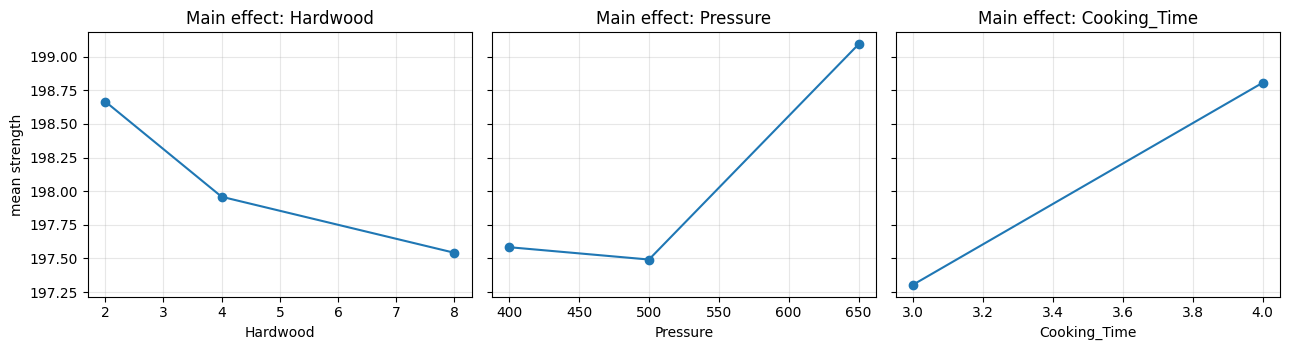

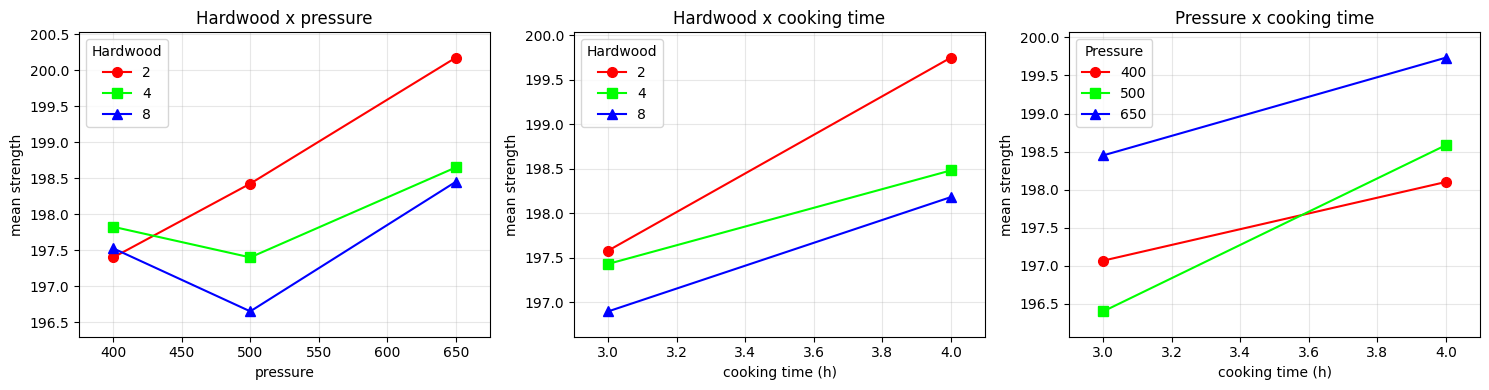

Marginal means:
  Hardwood: {2: 198.67, 4: 197.96, 8: 197.54}
  Pressure: {400: 197.58, 500: 197.49, 650: 199.09}
  Cooking_Time: {3: 197.31, 4: 198.81}

Hardwood x pressure cell means (averaged over cooking time and replicates):


Pressure,400,500,650
Hardwood,,,
2,197.40,198.42,200.18
4,197.82,197.40,198.65
8,197.52,196.65,198.45


Tukey's HSD for the main effects of hardwood and pressure (MS_E of the full model, 12 observations per level):
MS_E = 0.3656, df_E = 18, n per level = 12, HSD = 0.63


,pair,diff,lower,upper,p_adj,reject
0,4 - 2,-0.7083,-1.3383,-0.0784,0.0262,True
1,8 - 2,-1.1250,-1.7550,-0.4950,0.0007,True
2,8 - 4,-0.4167,-1.0466,0.2133,0.2368,False


MS_E = 0.3656, df_E = 18, n per level = 12, HSD = 0.63


,pair,diff,lower,upper,p_adj,reject
0,500 - 400,-0.0917,-0.7216,0.5383,0.9271,False
1,650 - 400,1.5083,0.8784,2.1383,0.0000,True
2,650 - 500,1.6000,0.9700,2.2300,0.0000,True


In [48]:
# Q1: three-factor ANOVA (alpha = 0.05), main-effect plots and interaction plots
m3_paper = smf.ols("Strength ~ C(Hardwood) * C(Pressure) * C(Cooking_Time)", data=paper).fit()
anova_paper = anova_report(m3_paper)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, f in zip(axes, ["Hardwood", "Pressure", "Cooking_Time"]):
    paper.groupby(f)["Strength"].mean().plot(marker="o", ax=ax)
    ax.set(title=f"Main effect: {f}", ylabel="mean strength")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
interaction_plot(paper["Pressure"], paper["Hardwood"], paper["Strength"], ax=axes[0], markers=["o", "s", "^"], ms=7)
axes[0].set(title="Hardwood x pressure", xlabel="pressure", ylabel="mean strength")
interaction_plot(paper["Cooking_Time"], paper["Hardwood"], paper["Strength"], ax=axes[1], markers=["o", "s", "^"], ms=7)
axes[1].set(title="Hardwood x cooking time", xlabel="cooking time (h)", ylabel="mean strength")
interaction_plot(paper["Cooking_Time"], paper["Pressure"], paper["Strength"], ax=axes[2], markers=["o", "s", "^"], ms=7)
axes[2].set(title="Pressure x cooking time", xlabel="cooking time (h)", ylabel="mean strength")
plt.tight_layout(); plt.show()

print("Marginal means:")
for f in ["Hardwood", "Pressure", "Cooking_Time"]:
    print(f"  {f}: {paper.groupby(f)['Strength'].mean().round(2).to_dict()}")
print("\nHardwood x pressure cell means (averaged over cooking time and replicates):")
display(paper.pivot_table(index="Hardwood", columns="Pressure", values="Strength", aggfunc="mean").round(2))
print("Tukey's HSD for the main effects of hardwood and pressure (MS_E of the full model, 12 observations per level):")
display(tukey_from_model(m3_paper, paper, "Hardwood", "Strength").round(4))
display(tukey_from_model(m3_paper, paper, "Pressure", "Strength").round(4))


With $MS_E = 0.366$ on 18 df:

| Effect | $F_0$ | df | $P$ | decision |
|---|---|---|---|---|
| hardwood $\times$ pressure $\times$ time | 1.35 | (4, 18) | 0.29 | not significant |
| hardwood $\times$ pressure | 4.17 | (4, 18) | 0.015 | **significant** |
| hardwood $\times$ time | 2.85 | (2, 18) | 0.084 | not significant (borderline) |
| pressure $\times$ time | 3.00 | (2, 18) | 0.075 | not significant (borderline) |
| hardwood | 10.62 | (2, 18) | 0.0009 | **significant** |
| pressure | 26.50 | (2, 18) | $4 \times 10^{-6}$ | **significant** |
| cooking time | 55.40 | (1, 18) | $7 \times 10^{-7}$ | **significant** |

All three main effects matter and hardwood and pressure interact. Cooking time acts (almost) additively: 4 h gives on average
1.5 units more strength than 3 h at every hardwood concentration and pressure (its two interactions are just above $\alpha$).
The hardwood $\times$ pressure interaction is a change of *shape*, not of direction: at 2 % hardwood the strength increases
steadily with pressure (197.4, 198.4, 200.2), at 4 % and 8 % it dips at 500 psi and recovers at 650 psi (197.8, 197.4, 198.7
and 197.5, 196.7, 198.5). Averaged over pressure, 2 % hardwood is better than 4 % (Tukey $P = 0.026$) and 8 % ($P = 0.0007$)
while 4 % and 8 % do not differ; 650 psi is better than 400 and 500 psi ($P < 10^{-4}$), which do not differ. The highest strength
is reached with little hardwood, high pressure and the longer cooking time.


**Question 2.** Prepare appropriate residual plots and comment on the model's adequacy.

**Procedure.** Residuals of the full three-factor model ($e = y - \bar y_{ijk\cdot}$, pairs $\pm r$ within each cell) against the
fitted values, on a normal probability plot and against each factor; Shapiro-Wilk test and Levene's test across the levels of
each factor.


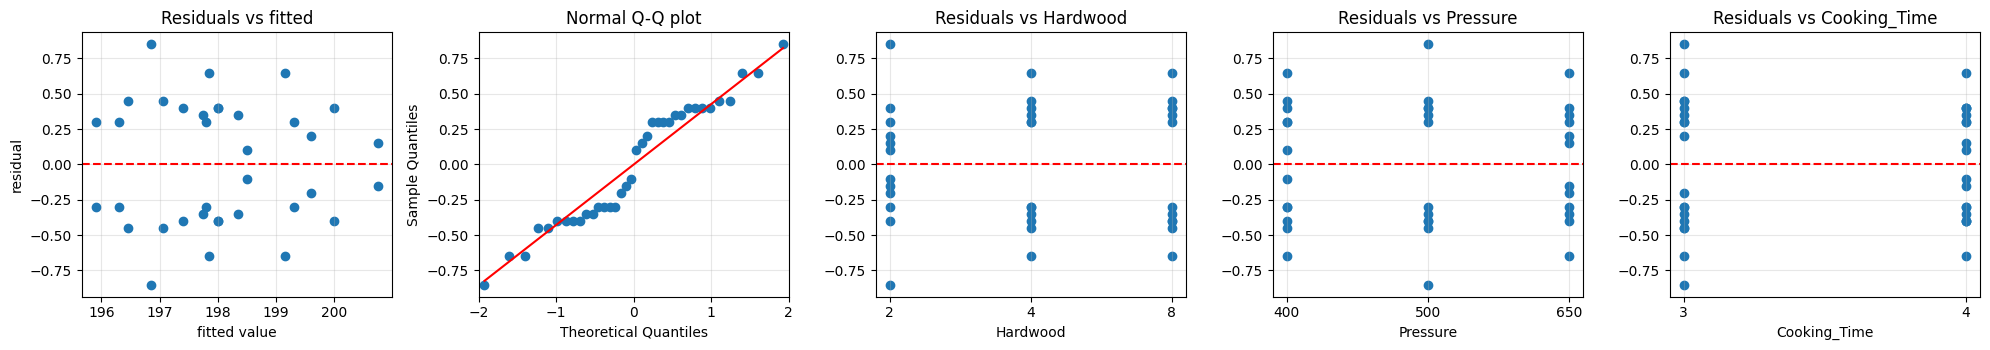

Shapiro-Wilk: W = 0.9390, P = 0.0472;  skewness = -0.00, excess kurtosis = -1.12
Levene (Brown-Forsythe) of the residuals across levels of Hardwood: W = 0.876, P = 0.4261
Levene (Brown-Forsythe) of the residuals across levels of Pressure: W = 1.430, P = 0.2538
Levene (Brown-Forsythe) of the residuals across levels of Cooking_Time: W = 2.927, P = 0.0962
largest |standardized residual| = 1.99


In [49]:
# Q2: residual analysis of the three-factor model
residual_plots(m3_paper, paper, ["Hardwood", "Pressure", "Cooking_Time"])


The residuals show no funnel against the fitted values and a similar spread at every level of hardwood, pressure and cooking time
(Levene $P = 0.43$, $0.25$ and $0.10$; the 3 h runs are slightly noisier than the 4 h runs). The normal probability plot shows flat
steps rather than a straight line and the Shapiro-Wilk test is borderline ($W = 0.94$, $P = 0.047$): with $n = 2$ the residuals
come in $\pm$ pairs, so their distribution is symmetric by construction (skewness 0), but it is flatter than normal (excess kurtosis
$-1.1$): most residuals sit at $\pm 0.3$ to $\pm 0.45$, few near zero and none in the far tails. The largest standardized residual
is 2.0, there are no outliers, and light tails are harmless for the $F$-test; the conclusions of Question 1 stand.


**Question 3.** Under what set of conditions would you operate this process? Why?

**Procedure.** Strength is to be maximised. Because hardwood and pressure interact, the choice is based on the hardwood $\times$
pressure cell means; cooking time enters additively (4 h is better everywhere). The fitted cell means of the full model are the
observed cell means, with standard error $\sqrt{MS_E/n}$ and standard error of a difference $\sqrt{2MS_E/n}$.


In [50]:
# Q3: operating conditions - ranking of the 18 treatment combinations
cell_means = (paper.groupby(["Hardwood", "Pressure", "Cooking_Time"])["Strength"]
              .agg(mean="mean", sd="std").reset_index().sort_values("mean", ascending=False))
se_mean, se_diff = np.sqrt(m3_paper.mse_resid / 2), np.sqrt(2 * m3_paper.mse_resid / 2)
print(f"standard error of a cell mean = {se_mean:.3f}, of a difference of two cell means = {se_diff:.3f}")
print("Six best treatment combinations:")
display(cell_means.head(6).round(2))
print("Hardwood x pressure means at 4 h cooking time:")
display(paper[paper["Cooking_Time"] == 4].pivot_table(index="Hardwood", columns="Pressure", values="Strength", aggfunc="mean").round(2))
print("Hardwood x pressure means at 3 h cooking time:")
display(paper[paper["Cooking_Time"] == 3].pivot_table(index="Hardwood", columns="Pressure", values="Strength", aggfunc="mean").round(2))


standard error of a cell mean = 0.428, of a difference of two cell means = 0.605
Six best treatment combinations:


,Hardwood,Pressure,Cooking_Time,mean,sd
5,2,650,4,200.75,0.21
3,2,500,4,200.00,0.57
4,2,650,3,199.60,0.28
11,4,650,4,199.30,0.42
17,8,650,4,199.15,0.92
1,2,400,4,198.50,0.14


Hardwood x pressure means at 4 h cooking time:


Pressure,400,500,650
Hardwood,,,
2,198.5,200.00,200.75
4,197.8,198.35,199.30
8,198.0,197.40,199.15


Hardwood x pressure means at 3 h cooking time:


Pressure,400,500,650
Hardwood,,,
2,196.30,196.85,199.60
4,197.85,196.45,198.00
8,197.05,195.90,197.75


The highest mean strength, 200.75, is obtained with **2 % hardwood, 650 psi and 4 h cooking time**, and every part of the
analysis supports this choice: 4 h beats 3 h at all nine hardwood/pressure combinations (main effect $+1.5$, $P < 10^{-6}$),
650 psi is the best pressure at every hardwood concentration, and 2 % hardwood is the best concentration at 500 and 650 psi and
gains most from raising the pressure. The runner-up, 2 % hardwood at 500 psi and 4 h (200.0), is within 1.3 standard errors of a
difference (0.60) of the best cell, so if the higher pressure were costly it would be an acceptable alternative. Conditions with
8 % hardwood or 3 h cooking give means of 199.2 or less (the only exception is 2 %/650 psi/3 h with 199.6) and should be avoided.


**Conclusions (Problem 5.18)**

* **ANOVA** ($MS_E = 0.366$ on 18 df): hardwood ($F_0 = 10.6$, $P = 0.0009$), pressure ($F_0 = 26.5$, $P = 4 \times 10^{-6}$) and
  cooking time ($F_0 = 55.4$, $P = 7 \times 10^{-7}$) all affect the strength; the hardwood $\times$ pressure interaction is
  significant ($F_0 = 4.17$, $P = 0.015$), the other interactions are not ($P = 0.075$ to $0.29$).
* **Interpretation.** Longer cooking (4 h) adds about 1.5 units everywhere; higher pressure (650 psi) helps at every hardwood level,
  most at 2 % hardwood; more hardwood lowers the strength (Tukey: 2 % $>$ 4 %, 8 %).
* **Assumptions.** Constant spread, no outliers; normality borderline (Shapiro-Wilk $P = 0.047$) but harmless for the $F$-tests.
* **Recommendation.** Operate at 2 % hardwood, 650 psi and 4 h (mean strength 200.75); 2 %/500 psi/4 h (200.0) is a close second.


### Problem 5.20: number of replicates (data of Problem 5.3)

The yield of a chemical process is studied at three pressures (200, 215, 230 psig) and three temperatures (150, 160, 170 $^\circ$C),
with two replicates (Problem 5.3).

In [51]:
yield_ = pd.read_csv(URL + "Chapter5_Pr01.csv", sep=";")
display(yield_.pivot_table(index="Temperature", columns="Pressure", values="Yield", aggfunc=list))

Pressure,200,215,230
Temperature,,,
150,"[90.4, 90.2]","[90.7, 90.6]","[90.2, 90.4]"
160,"[90.1, 90.3]","[90.5, 90.6]","[89.9, 90.1]"
170,"[90.5, 90.7]","[90.8, 90.9]","[90.1, 90.4]"


**Question 1.** (Problem 5.3) Analyse the data and draw conclusions ($\alpha = 0.05$).

**Hypotheses.** Two-factor fixed-effects factorial, $a = 3$ pressures, $b = 3$ temperatures, $n = 2$ ($N = 18$):

$$y_{ijk} = \mu + \tau_i + \beta_j + (\tau\beta)_{ij} + \varepsilon_{ijk}, \qquad \varepsilon_{ijk} \sim N(0, \sigma^2).$$

$H_0: (\tau\beta)_{ij} = 0$ ($F_{4,9}$), $H_0: \tau_i = 0$ for pressure ($F_{2,9}$) and $H_0: \beta_j = 0$ for temperature
($F_{2,9}$), all with $F_0 = MS_{\text{effect}} / MS_E$ and $df_E = ab(n-1) = 9$; significant main effects are followed by Tukey's
HSD with the full-model $MS_E$ ($bn = 6$ observations per level).


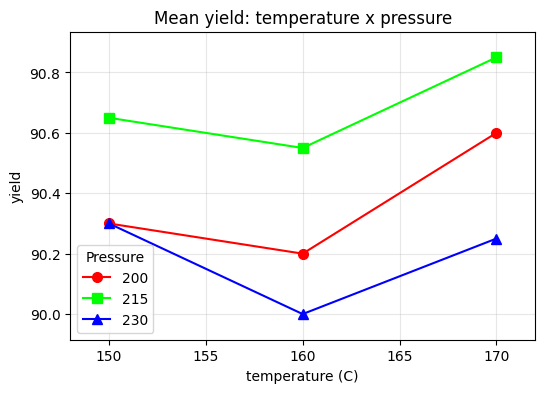

,sum_sq,df,F,PR(>F)
C(Pressure),0.7678,2.0,21.5937,0.0004
C(Temperature),0.3011,2.0,8.4687,0.0085
C(Pressure):C(Temperature),0.0689,4.0,0.9687,0.4700
Residual,0.1600,9.0,NaN,


MS_E = 0.0178 on 9 df
Pressure means:    {200: 90.367, 215: 90.683, 230: 90.183}
Temperature means: {150: 90.417, 160: 90.25, 170: 90.567}
MS_E = 0.01778, df_E = 9, n per level = 6, HSD = 0.2149


,pair,diff,lower,upper,p_adj,reject
0,215 - 200,0.3167,0.1017,0.5316,0.0067,True
1,230 - 200,-0.1833,-0.3983,0.0316,0.0945,False
2,230 - 215,-0.5000,-0.7149,-0.2851,0.0003,True


MS_E = 0.01778, df_E = 9, n per level = 6, HSD = 0.2149


,pair,diff,lower,upper,p_adj,reject
0,160 - 150,-0.1667,-0.3816,0.0483,0.1313,False
1,170 - 150,0.1500,-0.0649,0.3649,0.1809,False
2,170 - 160,0.3167,0.1017,0.5316,0.0067,True


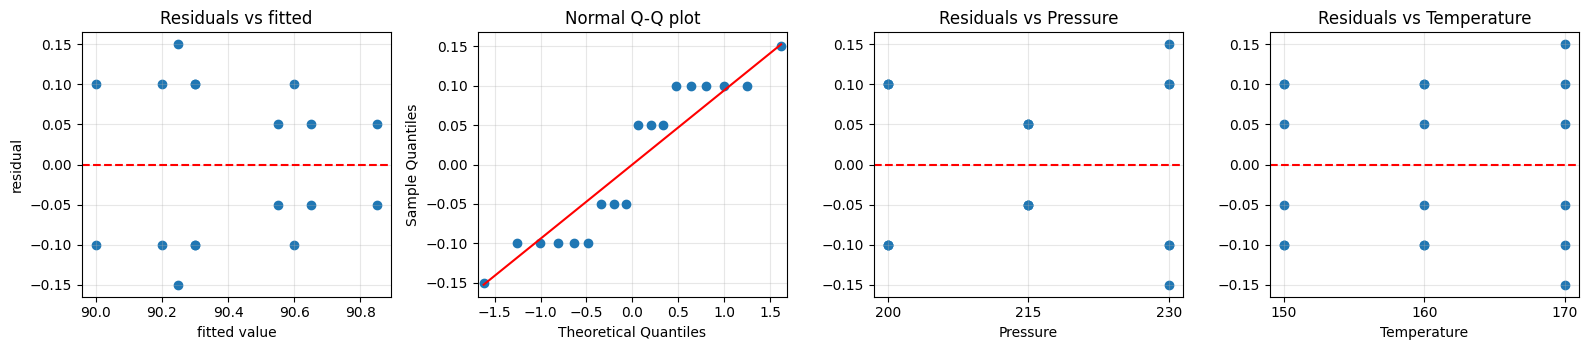

Shapiro-Wilk: W = 0.8737, P = 0.0205;  skewness = -0.00, excess kurtosis = -1.56
Levene (Brown-Forsythe) of the residuals across levels of Pressure: W = 32.500, P = 0.0000
Levene (Brown-Forsythe) of the residuals across levels of Temperature: W = 0.500, P = 0.6163
largest |standardized residual| = 1.59
Distinct residual values: [-0.15, -0.1, -0.05, 0.05, 0.1, 0.15]


In [52]:
# Q1 (Problem 5.3): interaction plot, ANOVA (alpha = 0.05), Tukey's HSD and residual check
fig, ax = plt.subplots(figsize=(6, 4))
interaction_plot(yield_["Temperature"], yield_["Pressure"], yield_["Yield"], ax=ax, markers=["o", "s", "^"], ms=7)
ax.set(title="Mean yield: temperature x pressure", xlabel="temperature (C)", ylabel="yield"); plt.show()

full_yield = smf.ols("Yield ~ C(Pressure) * C(Temperature)", data=yield_).fit()
anova_yield = anova_report(full_yield)
print("Pressure means:   ", yield_.groupby("Pressure")["Yield"].mean().round(3).to_dict())
print("Temperature means:", yield_.groupby("Temperature")["Yield"].mean().round(3).to_dict())
display(tukey_from_model(full_yield, yield_, "Pressure", "Yield").round(4))
display(tukey_from_model(full_yield, yield_, "Temperature", "Yield").round(4))
residual_plots(full_yield, yield_, ["Pressure", "Temperature"])
print("Distinct residual values:", sorted(full_yield.resid.round(3).unique()))


Interaction $F_0 = 0.97$ on (4, 9) df, $P = 0.47$: no interaction, the lines in the plot are roughly parallel. Pressure
$F_0 = 21.59$ on (2, 9) df, $P = 0.0004$ and temperature $F_0 = 8.47$ on (2, 9) df, $P = 0.0085$: **both main effects are
significant** ($MS_E = 0.0178$ on 9 df). Tukey's HSD ($T_{0.05} = 0.215$): 215 psig (mean 90.68) gives a higher yield than
200 psig (90.37, $P = 0.007$) and 230 psig (90.18, $P = 0.0003$), which do not differ; 170 $^\circ$C (90.57) beats 160 $^\circ$C
(90.25, $P = 0.007$) while 150 $^\circ$C (90.42) is not separated from either. The best setting is 215 psig and 170 $^\circ$C
(cell mean 90.85). All residuals are tiny ($|e| \le 0.15$). The yields are recorded to 0.1, so the residuals can only take the values
$\pm 0.05$, $\pm 0.10$, $\pm 0.15$: the staircase in the normal plot (Shapiro-Wilk $P = 0.02$) and the formally significant Levene
test across pressures (at 215 psig every replicate pair differs by exactly 0.1, at 230 psig by 0.2 to 0.3) are consequences of this
rounding and of having only two observations per cell, not evidence of a real departure from normality or of unequal variances;
across temperatures the spread is the same ($P = 0.62$).


**Question 2.** (Problem 5.20) We wish to reject the null hypothesis with a high probability if the difference in the true mean
yield at any two pressures is as great as 0.5. If a reasonable prior estimate of the standard deviation of yield is 0.1,
how many replicates should be run? Compute the power for $n = 2, 3, 4$ with `anova_power()`.

**Procedure.** (Problem 5.20.) Sample size for the pressure main effect ($a = 3$ levels, $b = 3$ temperatures, $n$ replicates per
cell). For a difference $D$ between two pressure means in the least favourable configuration (two means $D$ apart, the third in the
middle)

$$\Phi^2 = \frac{nbD^2}{2a\sigma^2}, \qquad \lambda = a\Phi^2 = \frac{nbD^2}{2\sigma^2}, \qquad F_0 \sim F_{a-1,\;ab(n-1)}(\lambda) \text{ under } H_1,$$

and the power is $1 - \beta = P\!\left(F_{2,\,9(n-1)}(\lambda) > F_{0.05;\,2,\,9(n-1)}\right)$, computed with `anova_power()`.
Here $D = 0.5$ and $\sigma = 0.1$.


In [53]:
# Q2 (Problem 5.20): power of the pressure F-test for n = 2, 3, 4 with D = 0.5 and sigma = 0.1
def power_table(D, sigma, a=3, b=3, ns=(2, 3, 4), alpha=0.05):
    rows = []
    for n in ns:
        lam = n * b * D**2 / (2 * sigma**2)
        df1, df2 = a - 1, a * b * (n - 1)
        rows.append({"n": n, "D": D, "sigma": round(sigma, 4), "Phi": np.sqrt(lam / a), "lambda": lam,
                     "df1": df1, "df2": df2, "power": anova_power(lam, df1, df2, alpha)})
    return pd.DataFrame(rows)

pw_q2 = power_table(D=0.5, sigma=0.1)
display(pw_q2.round(4))
print("power at n = 2 to more decimals:", f"{pw_q2['power'].iloc[0]:.6f}")


,n,D,sigma,Phi,lambda,df1,df2,power
0,2,0.5,0.1,5.0000,75.0,2,9,1.0
1,3,0.5,0.1,6.1237,112.5,2,18,1.0
2,4,0.5,0.1,7.0711,150.0,2,27,1.0


power at n = 2 to more decimals: 0.999999


With $D = 0.5$ and $\sigma = 0.1$ the noncentrality parameter is already $\lambda = 75$ ($\Phi = 5.0$) for $n = 2$, and the power is
$> 0.9999$ for $n = 2, 3, 4$. Two replicates, the design actually run in Problem 5.3, are more than enough to detect a difference
of 0.5 between two pressure means; indeed the observed difference of 0.50 between 215 and 230 psig was detected with $P = 0.0003$.
A single replicate is not an option, because with $n = 1$ the full model has no degrees of freedom for error.


**Question 3.** Repeat Question 2 with $\sigma$ estimated from the data of Problem 5.3 ($\hat\sigma = \sqrt{MS_E}$) and with a difference of 0.25. How sensitive is the required $n$ to these inputs?

**Procedure.** The same calculation with $\sigma$ replaced by the estimate from the data of Problem 5.3,
$\hat\sigma = \sqrt{MS_E} = \sqrt{0.0178} = 0.133$, and with the smaller difference $D = 0.25$; all four combinations are tabulated
for $n = 2, \dots, 6$, together with the smallest $n$ reaching power 0.80, 0.90 and 0.95. Halving $D$ divides $\lambda$ by 4;
replacing $\sigma = 0.1$ by 0.133 divides it by 1.78.


In [54]:
# Q3: sensitivity of the required number of replicates to sigma and D
sigma_hat = np.sqrt(full_yield.mse_resid)
print(f"sigma_hat = sqrt(MS_E) = sqrt({full_yield.mse_resid:.5f}) = {sigma_hat:.4f}  (prior guess 0.1)")
scenarios = [(0.5, 0.1), (0.5, sigma_hat), (0.25, 0.1), (0.25, sigma_hat)]
tabs = pd.concat([power_table(D, s, ns=range(2, 7)) for D, s in scenarios], ignore_index=True)
print("Power of the pressure F-test by scenario (columns: D, sigma):")
display(tabs.pivot(index="n", columns=["D", "sigma"], values="power").round(4))
req = []
for D, s in scenarios:
    t = power_table(D, s, ns=range(2, 31))
    req.append({"D": D, "sigma": round(s, 4), **{f"n for power >= {p}": int(t.loc[t["power"] >= p, "n"].min()) for p in (0.80, 0.90, 0.95)}})
display(pd.DataFrame(req))


sigma_hat = sqrt(MS_E) = sqrt(0.01778) = 0.1333  (prior guess 0.1)
Power of the pressure F-test by scenario (columns: D, sigma):


D       0.50            0.25        
sigma 0.1000  0.1333  0.1000  0.1333
n                                   
2        1.0  0.9988  0.9099  0.6849
3        1.0  1.0000  0.9946  0.9145
4        1.0  1.0000  0.9997  0.9794
5        1.0  1.0000  1.0000  0.9955
6        1.0  1.0000  1.0000  0.9991

,D,sigma,n for power >= 0.8,n for power >= 0.9,n for power >= 0.95
0,0.50,0.1000,2,2,2
1,0.50,0.1333,2,2,2
2,0.25,0.1000,2,2,3
3,0.25,0.1333,3,3,4


| $D$ | $\sigma$ | power at $n = 2$ | $n$ for power $\ge 0.90$ |
|---|---|---|---|
| 0.5 | 0.10 | 1.000 | 2 |
| 0.5 | 0.133 | 0.999 | 2 |
| 0.25 | 0.10 | 0.910 | 2 |
| 0.25 | 0.133 | 0.685 | 3 |

The required sample size is quite insensitive as long as the target difference stays at 0.5: even with the larger estimated
$\sigma$ two replicates give power 0.999. Halving the difference to 0.25 costs a factor of 4 in $\lambda$; with $\sigma = 0.1$ two
replicates are still just enough (0.91), but with the realistic $\hat\sigma = 0.133$ the power at $n = 2$ drops to 0.68 and three
replicates (0.91) are needed, four for power 0.95 (0.98). The number of replicates is driven by the ratio $D/\sigma$, which enters
$\lambda$ squared, so a modest change in either input can move the required $n$ by one or two replicates.


**Conclusions (Problems 5.3 and 5.20)**

* **ANOVA** ($MS_E = 0.0178$ on 9 df): pressure $F_0 = 21.6$, $P = 0.0004$ and temperature $F_0 = 8.47$, $P = 0.0085$ are
  significant, the interaction ($F_0 = 0.97$, $P = 0.47$) is not. Tukey's HSD ($T_{0.05} = 0.215$): 215 psig is better than 200 and
  230 psig, 170 $^\circ$C better than 160 $^\circ$C; the highest yield is at 215 psig and 170 $^\circ$C.
* **Assumptions.** All residuals lie within $\pm 0.15$; the staircase normal plot and the Levene result across pressures are artefacts
  of the yields being rounded to 0.1 with two observations per cell, not real violations.
* **Sample size.** To detect $D = 0.5$ with $\sigma = 0.1$, $n = 2$ replicates already give power $> 0.999$. With
  $\hat\sigma = 0.133$ from the data and $D = 0.25$, three replicates are needed for power 0.9 (four for 0.95); the requirement
  depends on $(D/\sigma)^2$.
